# Práctica 4 - Meta-aprendizaje y Ensambles de Clasificadores

**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - Centro de Investigación Científica y de Educación Superior de Ensenada (CICESE)  
**Autor -** Ruben Rivera Garcia  
**Repositorio -** [github.com/rubenriv2111-beep/ICD-2026](https://github.com/rubenriv2111-beep/ICD-2026)

---

## Planteamiento y Objetivos

El aprendizaje por ensambles combina múltiples hipótesis predictivas con la finalidad de reducir el error de generalización proveniente de la varianza, del sesgo o de limitaciones locales de cada familia algorítmica (Breiman, 1996; Freund & Schapire, 1997; Wolpert, 1992).

Esta práctica desarrolla dos bloques experimentales consecutivos.

1. **Parte 1 - Deserción estudiantil (`desercion-entrenamiento.csv`).** Sobre la misma partición estratificada en 5 pliegues empleada en la Práctica 3, se cuantifica cuánto ganan los métodos de ensamble respecto a los cinco clasificadores base previamente ajustados (Árbol de decisión, Naive Bayes, kNN, SVM y Regresión logística), evaluando Bagging con árboles profundos, AdaBoost con tocones, Votación dura, Votación suave con SVM calibrado, Stacking con meta-modelo logístico, correlación de errores y búsqueda de hiperparámetros en Random Forest, Extra-Trees, XGBoost y LightGBM.
2. **Parte 2 - Caso Bank Marketing (`bank-additional-full.csv`).** Con la exclusión estricta de `duration` frente a filtración de información (Moro et al., 2014), se evalúa un catálogo amplio de estrategias de preprocesamiento, ingeniería de atributos, balanceo por pesos, sobremuestreo `SMOTENC`, ajuste interno de umbral probabilístico, algoritmos individuales y ensambles optimizados bajo `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)` y métrica `f1_macro`, exportando el pipeline campeón final hacia disco.


In [1]:
import os
import time
import pickle
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import lightgbm as lgb
import imblearn
import joblib

from scipy.stats import randint, uniform, loguniform
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV,
    TunedThresholdClassifierCV,
    cross_validate,
    cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    FunctionTransformer,
    KBinsDiscretizer,
    Binarizer,
    TargetEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    make_scorer
)
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

# Semillas fijas institucionales
SEMILLA_P1 = 42
SEMILLA_BANK = 2026
np.random.seed(SEMILLA_P1)

# Paleta cromática institucional (Ruben Rivera Garcia - ICD 2026)
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
AZUL_CLARO = "#BFD5EA"
NARANJA = "#E76A28"
ROJO = "#C02B2B"
GRIS = "#5B6584"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9.5,
    "figure.dpi": 105,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "figure.titlesize": 12,
    "figure.titleweight": "bold"
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

print("Entorno configurado correctamente.")
print("numpy          =", np.__version__)
print("pandas         =", pd.__version__)
print("scipy          =", scipy.__version__)
print("scikit-learn   =", sklearn.__version__)
print("xgboost        =", xgb.__version__)
print("lightgbm       =", lgb.__version__)
print("imbalanced-lrn =", imblearn.__version__)
print("matplotlib     =", matplotlib.__version__)
print("seaborn        =", sns.__version__)
print("joblib         =", joblib.__version__)


Entorno configurado correctamente.
numpy          = 2.3.3
pandas         = 2.3.3
scipy          = 1.16.3
scikit-learn   = 1.7.2
xgboost        = 3.4.1
lightgbm       = 4.7.0
imbalanced-lrn = 0.14.2
matplotlib     = 3.10.7
seaborn        = 0.13.2
joblib         = 1.5.2


In [2]:
CACHE_P4 = "cache_practica4.pkl"

def cargar_o_calcular(clave, funcion_calculo):
    """Carga resultados previos si existe cache_practica4.pkl o los calcula en vivo."""
    if os.path.exists(CACHE_P4):
        try:
            with open(CACHE_P4, "rb") as archivo:
                datos_cache = pickle.load(archivo)
            if clave in datos_cache:
                return datos_cache[clave]
        except Exception:
            pass

    resultado = funcion_calculo()
    try:
        datos_cache = {}
        if os.path.exists(CACHE_P4):
            with open(CACHE_P4, "rb") as archivo:
                datos_cache = pickle.load(archivo)
        datos_cache[clave] = resultado
        archivo_tmp = CACHE_P4 + ".tmp"
        with open(archivo_tmp, "wb") as archivo:
            pickle.dump(datos_cache, archivo)
        os.replace(archivo_tmp, CACHE_P4)
    except Exception:
        pass
    return resultado

def recall_enrolled(y_real, y_pred):
    """Sensibilidad de la clase Enrolled (codificada como 1)."""
    return recall_score(y_real, y_pred, labels=[1], average="macro", zero_division=0)

def graficar_mesetas_doble(tabla_a, tabla_b, titulo_a, titulo_b, titulo_global):
    """Grafica curvas reales de convergencia acumulada sobre las iteraciones."""
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
    pares = [(axs[0], tabla_a, titulo_a, AZUL_OSCURO), (axs[1], tabla_b, titulo_b, NARANJA)]

    for ax, tabla, subtitulo, color_linea in pares:
        medias = tabla["mean_test_score"].to_numpy()
        iteraciones = np.arange(1, len(medias) + 1)
        acumulado = np.maximum.accumulate(medias)
        diferencias = np.diff(acumulado, prepend=acumulado[0] - 1.0)
        ultima_mejora = int(iteraciones[diferencias > 0].max())
        mejor_valor = float(acumulado[-1])

        ax.scatter(iteraciones, medias, s=18, alpha=0.45, color=AZUL, label="Configuración evaluada")
        ax.plot(iteraciones, acumulado, color=color_linea, linewidth=2.2, label="Mejor F1-macro acumulado")
        ax.axvline(ultima_mejora, color=GRIS, linestyle="--", linewidth=1.3)
        ax.text(
            min(ultima_mejora + 1.2, len(medias) * 0.72),
            mejor_valor - 0.012,
            "Última ganancia en iter. " + str(ultima_mejora),
            color=ROJO,
            fontsize=8.8,
            fontweight="bold"
        )
        ax.set_title(subtitulo)
        ax.set_xlabel("Iteración de búsqueda")
        ax.set_ylabel("F1-macro en validación cruzada")
        ax.set_ylim(max(0.45, medias.min() - 0.015), mejor_valor + 0.015)
        ax.legend(loc="lower right", frameon=True, facecolor="white")

    fig.suptitle(titulo_global, x=0.01, ha="left", y=1.02)
    plt.tight_layout()
    plt.show()

def resumir_hiperparametros(params_dict):
    """Formatea hiperparámetros limpios y compactos en una cadena legible."""
    partes = []
    for k, v in params_dict.items():
        nombre_corto = k.replace("modelo__", "").replace("clf__", "").replace("estimator__", "")
        if isinstance(v, (float, np.floating)):
            partes.append(nombre_corto + "=" + str(round(float(v), 4)))
        else:
            partes.append(nombre_corto + "=" + str(v))
    return ", ".join(partes)

print("Funciones auxiliares inicializadas.")


Funciones auxiliares inicializadas.


---

## Parte 1 - Deserción Estudiantil

El conjunto `desercion-entrenamiento.csv` reúne registros académicos de nivel superior procedentes del Instituto Politécnico de Portalegre (Realinho et al., 2021, 2022). Cada estudiante cuenta con 29 variables observables al cierre del primer semestre (factores demográficos, socioeconómicos, antecedentes escolares, rendimiento curricular temprano e indicadores macroeconómicos) y una etiqueta objetivo `Target` con tres categorías mutuamente excluyentes (`Dropout`, `Enrolled`, `Graduate`).

Siguiendo exactamente el protocolo experimental de la Práctica 3, todas las evaluaciones utilizan validación cruzada estratificada en 5 pliegues con semilla fija igual a 42 (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`), empleando $F_1$-macro como métrica rectora junto con la sensibilidad sobre la clase minoritaria crítica `Enrolled` y el tiempo medio de entrenamiento por pliegue.


In [3]:
df_desercion = pd.read_csv("desercion-entrenamiento.csv")

DEMOGRAFICAS = ["Marital status", "Nacionality", "Displaced", "Gender", "Age at enrollment", "International"]
SOCIOECONOMICAS = [
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
    "Educational special needs", "Debtor", "Tuition fees up to date", "Scholarship holder"
]
ANTECEDENTES = [
    "Application mode", "Application order", "Course", "Daytime/evening attendance",
    "Previous qualification", "Previous qualification (grade)"
]
PRIMER_SEM = [
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)"
]
MACROECONOMICOS = ["Unemployment rate", "Inflation rate", "GDP"]

ATRIBUTOS_P1 = DEMOGRAFICAS + SOCIOECONOMICAS + ANTECEDENTES + PRIMER_SEM + MACROECONOMICOS
NOMINALES_P1 = [
    "Marital status", "Nacionality", "Displaced", "Gender", "International",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
    "Educational special needs", "Debtor", "Tuition fees up to date", "Scholarship holder",
    "Application mode", "Course", "Daytime/evening attendance", "Previous qualification"
]
NUMERICOS_P1 = [col for col in ATRIBUTOS_P1 if col not in NOMINALES_P1]

MAPEO_P1 = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
CLASES_P1 = ["Dropout", "Enrolled", "Graduate"]

X_p1 = df_desercion[ATRIBUTOS_P1].copy()
y_p1 = df_desercion["Target"].map(MAPEO_P1).to_numpy()

PLIEGUES_P1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_P1)
splits_p1 = list(PLIEGUES_P1.split(X_p1, y_p1))

scoring_p1 = {
    "f1_macro": "f1_macro",
    "recall_enrolled": make_scorer(recall_enrolled)
}

print("Instancias de entrenamiento =", X_p1.shape[0], "| Atributos =", X_p1.shape[1])
conteo_p1 = pd.Series(df_desercion["Target"]).value_counts()
prop_p1 = pd.Series(df_desercion["Target"]).value_counts(normalize=True) * 100
for etiqueta in CLASES_P1:
    print("  Clase", etiqueta.ljust(10), "=", conteo_p1[etiqueta], "registros (", round(prop_p1[etiqueta], 2), "%)")


Instancias de entrenamiento = 3539 | Atributos = 29
  Clase Dropout    = 1137 registros ( 32.13 %)
  Clase Enrolled   = 635 registros ( 17.94 %)
  Clase Graduate   = 1767 registros ( 49.93 %)


### 1.1. Recuperación de los Cinco Clasificadores Base de la Práctica 3

Sin repetir su búsqueda de hiperparámetros, se reconstruyen los cinco pipelines ganadores de la Práctica 3 conservando idéntico preprocesamiento por familia.

1. **Árbol de decisión -** Codificación One-Hot con frecuencia mínima de 30, criterio entropía, profundidad máxima 8, hojas de al menos 32 muestras, poda `ccp_alpha = 0.001606` y ponderación balanceada.
2. **Naive Bayes -** Variante categórica (`CategoricalNB`) con codificación ordinal en nominales, discretización cuantílica de 6 intervalos en numéricas y suavizado `alpha = 0.03511`.
3. **kNN -** Estandarización numérica, One-Hot con peso nominal de 0.5, 19 vecinos, distancia Manhattan y votos ponderados por distancia.
4. **SVM -** Núcleo RBF, estandarización numérica, `C = 457.99`, `gamma = 0.000742` y peso doble en la clase `Enrolled`.
5. **Regresión logística -** Penalización ElasticNet (`l1_ratio = 0.2387`, `C = 0.2991`, solucionador SAGA), estandarización y peso doble en `Enrolled`.


In [4]:
def onehot_p1(min_freq):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)

def sumar_uno(matriz):
    return matriz + 1

# 1. Árbol de decisión P3
prep_arbol_p3 = ColumnTransformer([("nom", onehot_p1(30), NOMINALES_P1)], remainder="passthrough")
arbol_p3 = Pipeline([
    ("prep", prep_arbol_p3),
    ("modelo", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=8,
        min_samples_leaf=32,
        ccp_alpha=0.0016058927728864073,
        class_weight="balanced",
        random_state=SEMILLA_P1
    ))
])

# 2. Naive Bayes P3
nom_nb_p3 = Pipeline([
    ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=10)),
    ("mas1", FunctionTransformer(sumar_uno))
])
disc_nb_p3 = KBinsDiscretizer(n_bins=6, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf")
prep_nb_p3 = ColumnTransformer([("nom", nom_nb_p3, NOMINALES_P1), ("num", disc_nb_p3, NUMERICOS_P1)], remainder="passthrough")
nb_p3 = Pipeline([
    ("prep", prep_nb_p3),
    ("modelo", CategoricalNB(alpha=0.035113563139704075, fit_prior=True))
])

# 3. kNN P3 (incluyendo peso nominal 0.5)
prep_knn_p3 = ColumnTransformer(
    [("nom", onehot_p1(30), NOMINALES_P1), ("num", StandardScaler(), NUMERICOS_P1)],
    remainder="passthrough",
    transformer_weights={"nom": 0.5, "num": 1.0}
)
knn_p3 = Pipeline([
    ("prep", prep_knn_p3),
    ("modelo", KNeighborsClassifier(n_neighbors=19, weights="distance", metric="manhattan"))
])

# 4. SVM P3
prep_svm_p3 = ColumnTransformer([("nom", onehot_p1(30), NOMINALES_P1), ("num", StandardScaler(), NUMERICOS_P1)], remainder="passthrough")
svm_p3 = Pipeline([
    ("prep", prep_svm_p3),
    ("modelo", SVC(
        kernel="rbf",
        C=457.9888558216176,
        gamma=0.0007415234675931621,
        class_weight={0: 1.0, 1: 2.0, 2: 1.0},
        random_state=SEMILLA_P1
    ))
])

# 5. Regresión Logística P3
prep_lr_p3 = ColumnTransformer([("nom", onehot_p1(10), NOMINALES_P1), ("num", StandardScaler(), NUMERICOS_P1)], remainder="passthrough")
lr_p3 = Pipeline([
    ("prep", prep_lr_p3),
    ("modelo", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        C=0.2991469302130217,
        l1_ratio=0.23869172280621767,
        class_weight={0: 1.0, 1: 2.0, 2: 1.0},
        max_iter=2000,
        random_state=SEMILLA_P1
    ))
])

modelos_base_p3 = [
    ("arbol", "Árbol de decisión (P3)", arbol_p3, "entropy, depth=8, min_leaf=32, balanced"),
    ("nb", "Naive Bayes (P3)", nb_p3, "CategoricalNB, n_bins=6, alpha=0.0351"),
    ("knn", "kNN (P3)", knn_p3, "k=19, manhattan, distance, w_nom=0.5"),
    ("svm", "SVM (P3)", svm_p3, "rbf, C=458.0, gamma=0.00074, w_Enrolled=2"),
    ("lr", "Regresión logística (P3)", lr_p3, "elasticnet, C=0.299, l1_ratio=0.239, w_Enrolled=2")
]

def calcular_base_p3():
    registros = []
    for clave_corta, nombre_largo, pipe, cfg in modelos_base_p3:
        cv_res = cross_validate(pipe, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)
        registros.append({
            "clave": clave_corta,
            "Modelo": nombre_largo,
            "F1-macro": float(cv_res["test_f1_macro"].mean()),
            "Desv. Est.": float(cv_res["test_f1_macro"].std()),
            "Sensibilidad Enrolled": float(cv_res["test_recall_enrolled"].mean()),
            "Tiempo Fit (s)": float(cv_res["fit_time"].mean()),
            "Mejor Configuración": cfg
        })
    return registros

res_base_p3 = cargar_o_calcular("p1_base_p3", calcular_base_p3)
tabla_base_p3 = pd.DataFrame(res_base_p3).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_base_p3["F1-macro (media +/- desv.)"] = (
    tabla_base_p3["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_base_p3["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 1 - Desempeño verificado de los cinco clasificadores base (Práctica 3)")
display(tabla_base_p3[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)", "Mejor Configuración"]].round(4))


Tabla 1 - Desempeño verificado de los cinco clasificadores base (Práctica 3)


,Modelo,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s),Mejor Configuración
0,SVM (P3),0.6815 +/- 0.0088,0.5528,0.6008,"rbf, C=458.0, gamma=0.00074, w_Enrolled=2"
1,Regresión logística (P3),0.6798 +/- 0.0068,0.5165,1.7499,"elasticnet, C=0.299, l1_ratio=0.239, w_Enrolled=2"
2,Árbol de decisión (P3),0.6489 +/- 0.0110,0.6457,0.0425,"entropy, depth=8, min_leaf=32, balanced"
3,Naive Bayes (P3),0.6242 +/- 0.0117,0.4205,0.0232,"CategoricalNB, n_bins=6, alpha=0.0351"
4,kNN (P3),0.5657 +/- 0.0157,0.1496,0.0187,"k=19, manhattan, distance, w_nom=0.5"


#### Interpretación de la Tabla 1

Los resultados replican fielmente la jerarquía observada en la Práctica 3 sobre los mismos cinco pliegues estratificados. SVM y Regresión logística encabezan el rendimiento individual al rondar un $F_1$-macro cercano a 0.68 y capturar más de la mitad de los estudiantes inscritos (`Enrolled`), seguidos por el Árbol de decisión con poda, Naive Bayes categórico y kNN. Este piso de referencia resulta indispensable con el fin de evaluar cuánto valor añaden después los esquemas de ensamble sobre modelos ya sintonizados.


### 1.2. Reducción de Varianza - Árbol sin Límite y Bagging

Un árbol de decisión sin límite de profundidad (`max_depth=None`) continúa dividiendo nodos hasta purificar las hojas del conjunto de entrenamiento, exhibiendo una varianza muy alta frente a ligeras perturbaciones muestrales. El algoritmo Bagging (*Bootstrap Aggregating*) entrena múltiples réplicas de ese estimador inestable sobre muestras bootstrap independientes con reemplazo y agrega sus decisiones por votación.

En el código siguiente se evalúa primero el árbol sin restricción y se construye progresivamente el ensamble de Bagging utilizando `warm_start=True` dentro de cada pliegue, incorporando árboles hasta alcanzar 400 unidades (`[1, 5, 10, 20, 50, 100, 200, 300, 400]`).


In [5]:
cantidades_arboles = [1, 5, 10, 20, 50, 100, 200, 300, 400]

def calcular_varianza_bagging():
    arbol_libre = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", DecisionTreeClassifier(max_depth=None, random_state=SEMILLA_P1))
    ])
    res_libre = cross_validate(
        arbol_libre, X_p1, y_p1, cv=splits_p1,
        scoring=scoring_p1, return_train_score=True, n_jobs=-1
    )

    f1_por_n = {n: [] for n in cantidades_arboles}
    rec_por_n = {n: [] for n in cantidades_arboles}
    tiempos_por_n = {n: [] for n in cantidades_arboles}

    for tr_idx, va_idx in splits_p1:
        X_tr, X_va = X_p1.iloc[tr_idx], X_p1.iloc[va_idx]
        y_tr, y_va = y_p1[tr_idx], y_p1[va_idx]

        prep_fold = clone(prep_arbol_p3)
        X_tr_enc = prep_fold.fit_transform(X_tr)
        X_va_enc = prep_fold.transform(X_va)

        bag = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=None, random_state=SEMILLA_P1),
            n_estimators=1,
            bootstrap=True,
            warm_start=True,
            random_state=SEMILLA_P1,
            n_jobs=1
        )
        tiempo_acumulado = 0.0
        for n in cantidades_arboles:
            t_ini = time.perf_counter()
            bag.set_params(n_estimators=n)
            bag.fit(X_tr_enc, y_tr)
            tiempo_acumulado += (time.perf_counter() - t_ini)

            preds = bag.predict(X_va_enc)
            f1_por_n[n].append(float(f1_score(y_va, preds, average="macro")))
            rec_por_n[n].append(float(recall_enrolled(y_va, preds)))
            tiempos_por_n[n].append(float(tiempo_acumulado))

    filas_bag = []
    for n in cantidades_arboles:
        filas_bag.append({
            "Árboles": n,
            "F1-macro": float(np.mean(f1_por_n[n])),
            "Desv. Est.": float(np.std(f1_por_n[n])),
            "Sensibilidad Enrolled": float(np.mean(rec_por_n[n])),
            "Tiempo Fit (s)": float(np.mean(tiempos_por_n[n]))
        })

    return {
        "libre": {
            "train_f1": float(res_libre["train_f1_macro"].mean()),
            "F1-macro": float(res_libre["test_f1_macro"].mean()),
            "Desv. Est.": float(res_libre["test_f1_macro"].std()),
            "Sensibilidad Enrolled": float(res_libre["test_recall_enrolled"].mean()),
            "Tiempo Fit (s)": float(res_libre["fit_time"].mean())
        },
        "curva": filas_bag
    }

datos_var = cargar_o_calcular("p1_varianza_bagging", calcular_varianza_bagging)
info_libre = datos_var["libre"]
tabla_bagging = pd.DataFrame(datos_var["curva"])
tabla_bagging["F1-macro (media +/- desv.)"] = (
    tabla_bagging["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_bagging["Desv. Est."].map("{:.4f}".format)
)

print("Árbol sin límite -> F1-macro entrenamiento =", round(info_libre["train_f1"], 4),
      "| F1-macro validación =", round(info_libre["F1-macro"], 4), "+/-", round(info_libre["Desv. Est."], 4))
print()
print("Tabla 2 - Evolución progresiva de Bagging con warm_start=True (1 a 400 árboles)")
display(tabla_bagging[["Árboles", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)"]].round(4))


Árbol sin límite -> F1-macro entrenamiento = 1.0 | F1-macro validación = 0.5854 +/- 0.0107

Tabla 2 - Evolución progresiva de Bagging con warm_start=True (1 a 400 árboles)


,Árboles,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s)
0,1,0.5895 +/- 0.0136,0.3291,0.0194
1,5,0.6248 +/- 0.0186,0.3213,0.0909
2,10,0.6365 +/- 0.0099,0.3118,0.1838
3,20,0.6549 +/- 0.0069,0.3307,0.3876
4,50,0.6565 +/- 0.0152,0.3307,1.0124
5,100,0.6542 +/- 0.0198,0.3197,1.9164
6,200,0.6617 +/- 0.0261,0.3323,3.7815
7,300,0.6630 +/- 0.0256,0.3323,5.7413
8,400,0.6610 +/- 0.0278,0.3291,7.6235


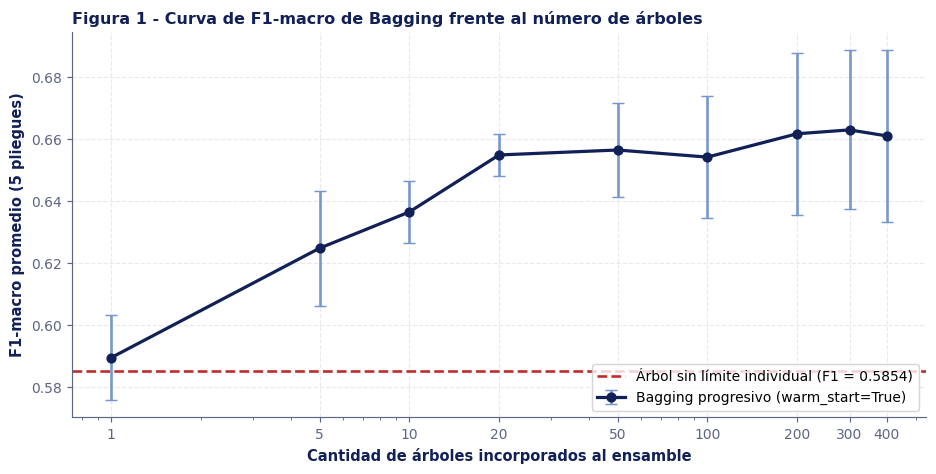

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))

ax.errorbar(
    tabla_bagging["Árboles"],
    tabla_bagging["F1-macro"],
    yerr=tabla_bagging["Desv. Est."],
    fmt="-o",
    color=AZUL_OSCURO,
    ecolor=AZUL,
    elinewidth=1.8,
    capsize=4,
    linewidth=2.2,
    markersize=6,
    label="Bagging progresivo (warm_start=True)"
)
ax.axhline(
    info_libre["F1-macro"],
    color=ROJO,
    linestyle="--",
    linewidth=1.8,
    label="Árbol sin límite individual (F1 = " + str(round(info_libre["F1-macro"], 4)) + ")"
)

ax.set_title("Figura 1 - Curva de F1-macro de Bagging frente al número de árboles")
ax.set_xlabel("Cantidad de árboles incorporados al ensamble")
ax.set_ylabel("F1-macro promedio (5 pliegues)")
ax.set_xscale("log")
ax.set_xticks(cantidades_arboles)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


#### Interpretación de la Figura 1 y la Tabla 2

El árbol individual sin límite de profundidad alcanza un $F_1$-macro perfecto en entrenamiento (1.0000) que cae drásticamente hacia 0.5854 en validación, confirmando un sobreajuste pronunciado. Con apenas un árbol bootstrap, Bagging parte en 0.5895; al incorporar réplicas mediante `warm_start=True`, el puntaje asciende con rapidez durante los primeros 20 a 50 árboles y alcanza su pico en 0.6630 con 300 estimadores (estabilizándose en 0.6610 hacia los 400), ganando cerca de 7.8 puntos porcentuales respecto al árbol aislado.

#### Respuesta - ¿Qué reduce bagging, y por qué?

Bagging reduce primordialmente la **varianza** del estimador sin aumentar su sesgo original. Cada árbol profundo individual posee bajo sesgo y elevada inestabilidad frente a cambios muestrales; al promediar cientos de árboles entrenados sobre distintas muestras bootstrap, las fluctuaciones aleatorias y errores particulares de cada árbol se cancelan mutuamente en proporción a la covarianza promedio entre ellos, estabilizando la frontera de decisión (Breiman, 1996).


### 1.3. Reducción de Sesgo - Tocón y AdaBoost con Tocones

En el extremo opuesto del espectro se encuentra un tocón de decisión (`max_depth=1`), el cual realiza una única partición lineal sobre un atributo. Su simplicidad estructural limita la varianza al mínimo, a costa de un sesgo elevado e incapacidad de modelar fronteras complejas.

El algoritmo AdaBoost entrena una secuencia de tocones reponderando en cada ronda las instancias mal clasificadas en etapas previas (Freund & Schapire, 1997). Utilizando `staged_predict()`, se registra la evolución exacta de la métrica desde la ronda 1 hasta la ronda 400 dentro de cada pliegue estratificado.


In [7]:
rondas_clave = [1, 5, 10, 20, 50, 100, 200, 300, 400]

def calcular_sesgo_adaboost():
    tocon_pipe = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", DecisionTreeClassifier(max_depth=1, random_state=SEMILLA_P1))
    ])
    res_tocon = cross_validate(
        tocon_pipe, X_p1, y_p1, cv=splits_p1,
        scoring=scoring_p1, return_train_score=True, n_jobs=-1
    )

    f1_todas_rondas = np.zeros((5, 400))
    rec_rondas_clave = {r: [] for r in rondas_clave}
    tiempos_ada = []

    for fold_i, (tr_idx, va_idx) in enumerate(splits_p1):
        X_tr, X_va = X_p1.iloc[tr_idx], X_p1.iloc[va_idx]
        y_tr, y_va = y_p1[tr_idx], y_p1[va_idx]

        prep_fold = clone(prep_arbol_p3)
        X_tr_enc = prep_fold.fit_transform(X_tr)
        X_va_enc = prep_fold.transform(X_va)

        ada = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, random_state=SEMILLA_P1),
            n_estimators=400,
            learning_rate=1.0,
            random_state=SEMILLA_P1
        )
        t_ini = time.perf_counter()
        ada.fit(X_tr_enc, y_tr)
        tiempos_ada.append(float(time.perf_counter() - t_ini))

        for ronda, preds_etapa in enumerate(ada.staged_predict(X_va_enc), start=1):
            f1_todas_rondas[fold_i, ronda - 1] = float(f1_score(y_va, preds_etapa, average="macro"))
            if ronda in rec_rondas_clave:
                rec_rondas_clave[ronda].append(float(recall_enrolled(y_va, preds_etapa)))

    curva_media = f1_todas_rondas.mean(axis=0).tolist()
    curva_sd = f1_todas_rondas.std(axis=0).tolist()

    filas_ada = []
    for r in rondas_clave:
        filas_ada.append({
            "Rondas": r,
            "F1-macro": float(curva_media[r - 1]),
            "Desv. Est.": float(curva_sd[r - 1]),
            "Sensibilidad Enrolled": float(np.mean(rec_rondas_clave[r]))
        })

    return {
        "tocon": {
            "train_f1": float(res_tocon["train_f1_macro"].mean()),
            "F1-macro": float(res_tocon["test_f1_macro"].mean()),
            "Desv. Est.": float(res_tocon["test_f1_macro"].std()),
            "Sensibilidad Enrolled": float(res_tocon["test_recall_enrolled"].mean()),
            "Tiempo Fit (s)": float(res_tocon["fit_time"].mean())
        },
        "curva_media": curva_media,
        "curva_sd": curva_sd,
        "tabla_clave": filas_ada,
        "tiempo_fit_400": float(np.mean(tiempos_ada))
    }

datos_sesgo = cargar_o_calcular("p1_sesgo_adaboost", calcular_sesgo_adaboost)
info_tocon = datos_sesgo["tocon"]
tabla_adaboost = pd.DataFrame(datos_sesgo["tabla_clave"])
tabla_adaboost["F1-macro (media +/- desv.)"] = (
    tabla_adaboost["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_adaboost["Desv. Est."].map("{:.4f}".format)
)

print("Tocón individual -> F1-macro entrenamiento =", round(info_tocon["train_f1"], 4),
      "| F1-macro validación =", round(info_tocon["F1-macro"], 4), "+/-", round(info_tocon["Desv. Est."], 4))
print("Tiempo medio de ajuste AdaBoost (400 rondas) =", round(datos_sesgo["tiempo_fit_400"], 2), "s")
print()
print("Tabla 3 - Desempeño de AdaBoost mediante staged_predict() en rondas clave")
display(tabla_adaboost[["Rondas", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled"]].round(4))


Tocón individual -> F1-macro entrenamiento = 0.492 | F1-macro validación = 0.492 +/- 0.0121
Tiempo medio de ajuste AdaBoost (400 rondas) = 1.67 s

Tabla 3 - Desempeño de AdaBoost mediante staged_predict() en rondas clave


,Rondas,F1-macro (media +/- desv.),Sensibilidad Enrolled
0,1,0.4920 +/- 0.0121,0.0000
1,5,0.4935 +/- 0.0095,0.0000
2,10,0.5156 +/- 0.0154,0.0173
3,20,0.5378 +/- 0.0184,0.0457
4,50,0.5656 +/- 0.0056,0.0850
5,100,0.6196 +/- 0.0145,0.2000
6,200,0.6329 +/- 0.0089,0.2409
7,300,0.6354 +/- 0.0074,0.2441
8,400,0.6443 +/- 0.0095,0.2693


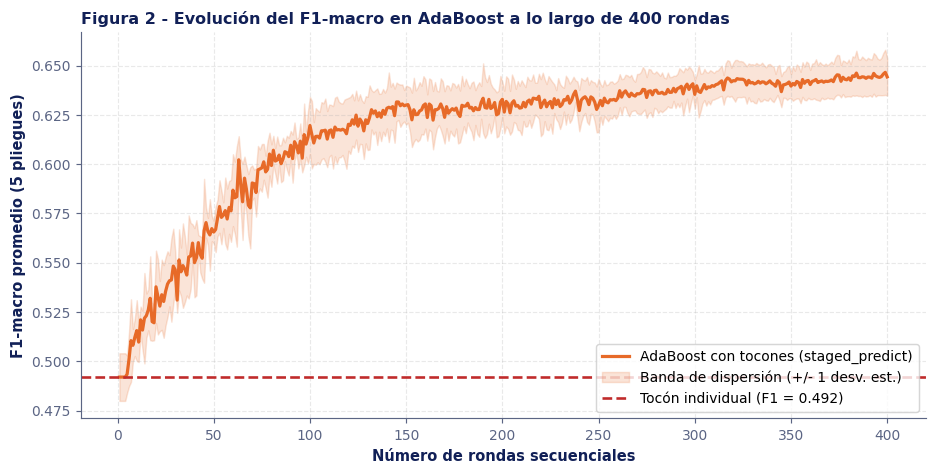

In [8]:
rondas_eje = np.arange(1, 401)
curva_ada_m = np.array(datos_sesgo["curva_media"])
curva_ada_s = np.array(datos_sesgo["curva_sd"])

fig, ax = plt.subplots(figsize=(9, 4.6))

ax.plot(rondas_eje, curva_ada_m, color=NARANJA, linewidth=2.2, label="AdaBoost con tocones (staged_predict)")
ax.fill_between(
    rondas_eje, curva_ada_m - curva_ada_s, curva_ada_m + curva_ada_s,
    color=NARANJA, alpha=0.18, label="Banda de dispersión (+/- 1 desv. est.)"
)
ax.axhline(
    info_tocon["F1-macro"], color=ROJO, linestyle="--", linewidth=1.8,
    label="Tocón individual (F1 = " + str(round(info_tocon["F1-macro"], 4)) + ")"
)

ax.set_title("Figura 2 - Evolución del F1-macro en AdaBoost a lo largo de 400 rondas")
ax.set_xlabel("Número de rondas secuenciales")
ax.set_ylabel("F1-macro promedio (5 pliegues)")
ax.legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


#### Interpretación de la Figura 2 y la Tabla 3

El tocón individual registra exactamente el mismo puntaje en entrenamiento y validación (0.4920), incapaz de reconocer la clase `Enrolled` (sensibilidad 0.0000). A medida que AdaBoost ejecuta rondas secuenciales, el $F_1$-macro crece de forma sostenida hasta superar 0.619 en la ronda 100 y alcanzar 0.6443 en la ronda 400, rescatando progresivamente la sensibilidad sobre estudiantes matriculados (hasta 0.2693) sin degradar la estabilidad entre pliegues.

#### Respuesta - ¿Qué reduce boosting, y por qué?

Boosting reduce fundamentalmente el **sesgo** del modelo. En cada iteración, el algoritmo incrementa el peso relativo de las observaciones erróneamente clasificadas, forzando al siguiente tocón a concentrarse en las regiones difíciles del espacio de atributos. La suma ponderada aditiva de cientos de hipótesis simples conforma una frontera no lineal de alta capacidad expresiva que corrige el subajuste inicial (Freund & Schapire, 1997; Schapire & Freund, 2012).


### 1.4. Combinación de los Cinco Clasificadores Base y Correlación de Errores

Los cinco algoritmos base recuperados de la Práctica 3 pertenecen a familias conceptualmente distintas (particiones ortogonales por árbol, verosimilitud discreta, vecindad geométrica Manhattan, hiperplano RBF y frontera lineal regularizada). Se contrastan tres estrategias de integración sobre los mismos cinco pliegues estratificados.

- **Votación dura (`VotingClassifier(voting="hard")`) -** Adopta la clase elegida por mayoría simple de etiquetas.
- **Votación suave (`VotingClassifier(voting="soft")`) -** Promedia las probabilidades estimadas; puesto que `SVC` no produce probabilidades calibradas nativamente, se envuelve en `CalibratedClassifierCV(method="sigmoid", cv=3)` ajustado estrictamente dentro de cada partición de entrenamiento.
- **Stacking (`StackingClassifier`) -** Entrena un meta-modelo de regresión logística sobre las probabilidades fuera de muestra producidas mediante validación interna (`cv=5`), evaluándose el esquema completo con `cross_validate` (Wolpert, 1992).


In [9]:
def calcular_combinacion_p3():
    svm_calibrado = CalibratedClassifierCV(
        estimator=clone(svm_p3),
        method="sigmoid",
        cv=3
    )

    estimadores_duros = [
        ("arbol", clone(arbol_p3)),
        ("nb", clone(nb_p3)),
        ("knn", clone(knn_p3)),
        ("svm", clone(svm_p3)),
        ("lr", clone(lr_p3))
    ]
    estimadores_prob = [
        ("arbol", clone(arbol_p3)),
        ("nb", clone(nb_p3)),
        ("knn", clone(knn_p3)),
        ("svm", svm_calibrado),
        ("lr", clone(lr_p3))
    ]

    vot_dura = VotingClassifier(estimators=estimadores_duros, voting="hard", n_jobs=1)
    vot_suave = VotingClassifier(estimators=estimadores_prob, voting="soft", n_jobs=1)
    stacking_log = StackingClassifier(
        estimators=estimadores_prob,
        final_estimator=LogisticRegression(max_iter=2000, random_state=SEMILLA_P1),
        stack_method="predict_proba",
        cv=5,
        n_jobs=1
    )

    resultados_ens = []
    for nom, ens in [
        ("Votación dura (5 base)", vot_dura),
        ("Votación suave (5 base)", vot_suave),
        ("Stacking logístico (5 base)", stacking_log)
    ]:
        cv_r = cross_validate(ens, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)
        resultados_ens.append({
            "Modelo": nom,
            "F1-macro": float(cv_r["test_f1_macro"].mean()),
            "Desv. Est.": float(cv_r["test_f1_macro"].std()),
            "Sensibilidad Enrolled": float(cv_r["test_recall_enrolled"].mean()),
            "Tiempo Fit (s)": float(cv_r["fit_time"].mean()),
            "Mejor Configuración": "5 modelos P3" if "dura" in nom else ("5 modelos P3 + SVM calibrado" if "suave" in nom else "Meta=Reg. Logística, cv=5, SVM calibrado")
        })
    return resultados_ens

res_comb_p3 = cargar_o_calcular("p1_combinacion_p3", calcular_combinacion_p3)
tabla_comb_p3 = pd.DataFrame(res_comb_p3).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_comb_p3["F1-macro (media +/- desv.)"] = (
    tabla_comb_p3["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_comb_p3["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 4 - Comparativa de estrategias de combinación sobre los cinco modelos base")
display(tabla_comb_p3[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)", "Mejor Configuración"]].round(4))


Tabla 4 - Comparativa de estrategias de combinación sobre los cinco modelos base


,Modelo,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s),Mejor Configuración
0,Votación dura (5 base),0.6846 +/- 0.0058,0.5008,2.4846,5 modelos P3
1,Votación suave (5 base),0.6717 +/- 0.0082,0.4079,2.2892,5 modelos P3 + SVM calibrado
2,Stacking logístico (5 base),0.6716 +/- 0.0139,0.3512,13.0729,"Meta=Reg. Logística, cv=5, SVM calibrado"


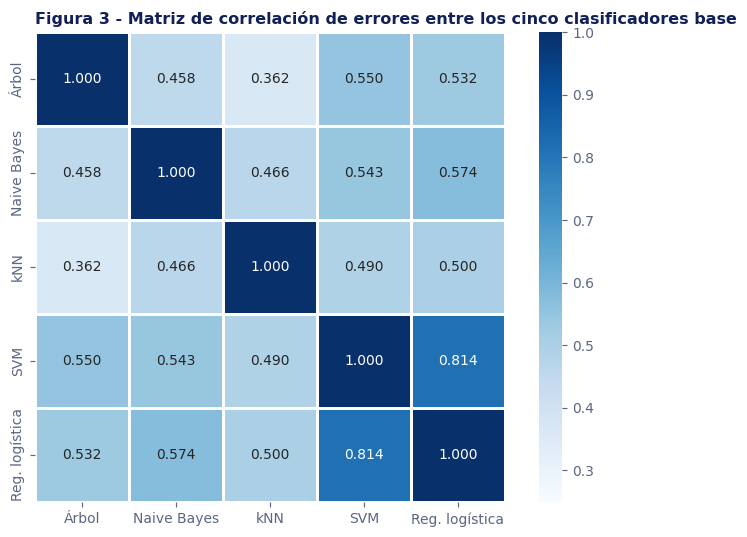

In [10]:
def calcular_correlacion_errores():
    errores = pd.DataFrame(index=X_p1.index)
    for clave_corta, _, pipe, _ in modelos_base_p3:
        preds_oof = cross_val_predict(clone(pipe), X_p1, y_p1, cv=splits_p1, n_jobs=-1)
        errores[clave_corta] = (preds_oof != y_p1).astype(int)
    return errores.corr()

matriz_corr_errores = cargar_o_calcular("p1_corr_errores", calcular_correlacion_errores)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
nombres_ejes = ["Árbol", "Naive Bayes", "kNN", "SVM", "Reg. logística"]
sns.heatmap(
    matriz_corr_errores,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=nombres_ejes,
    yticklabels=nombres_ejes,
    vmin=0.25,
    vmax=1.0,
    square=True,
    linewidths=0.9,
    linecolor="white",
    ax=ax
)
ax.grid(False)
ax.set_title("Figura 3 - Matriz de correlación de errores entre los cinco clasificadores base")
plt.tight_layout()
plt.show()


#### Interpretación de la Tabla 4 y la Figura 3

La votación dura supera a todos y cada uno de los cinco clasificadores base individuales, elevando el $F_1$-macro hasta 0.6846 con la menor dispersión entre pliegues (0.0058). Por oposición, la votación suave (0.6717) y el stacking logístico (0.6716) rinden ligeramente por debajo de SVM (0.6815) y Regresión logística (0.6798) individuales, ya que la recalibración sigmoidal y las diferencias de escala probabilística entre `CategoricalNB`, kNN ponderado y el árbol podado diluyen las fronteras limpias del consenso por voto discreto.

#### Respuesta - ¿Qué tan correlacionados están los errores de los cinco clasificadores y qué implica?

Los errores exhiben una correlación heterogénea, variando desde niveles bajos cercanos a 0.362 entre el Árbol de decisión y kNN hasta una asociación alta de 0.814 entre SVM y Regresión logística. Esta estructura implica que las familias algorítmicas distintas fallan sobre estudiantes diferentes, aportando la **diversidad predictiva** necesaria que faculta a la votación dura a cancelar equivocaciones aisladas y elevar la generalización colectiva; simultáneamente, la alta redundancia entre SVM y Regresión logística limita la información independiente que logra extraer un meta-modelo lineal en Stacking (Kuncheva, 2004).


### 1.5. Bagging Optimizado - Random Forest y Extra-Trees

Se ejecutan búsquedas aleatorias (`RandomizedSearchCV`, 50 configuraciones por modelo sobre `PLIEGUES_P1`) manteniendo todo preprocesamiento encapsulado dentro de `Pipeline`. Se exploran `n_estimators`, `max_features`, `max_depth`, `min_samples_leaf`, `criterion` (`gini`, `entropy`, `log_loss`), `class_weight` y, de forma particular en Extra-Trees, el uso o prescindencia de `bootstrap` (Breiman, 2001; Geurts et al., 2006).


In [11]:
def optimizar_bagging_p1():
    espacio_rf = {
        "modelo__n_estimators": randint(100, 401),
        "modelo__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
        "modelo__max_depth": [6, 8, 10, 14, 20, None],
        "modelo__min_samples_leaf": [1, 2, 4, 8, 16],
        "modelo__criterion": ["gini", "entropy", "log_loss"],
        "modelo__class_weight": [None, "balanced", "balanced_subsample", {0: 1.0, 1: 1.5, 2: 1.0}, {0: 1.0, 1: 2.0, 2: 1.0}]
    }
    pipe_rf = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", RandomForestClassifier(random_state=SEMILLA_P1, n_jobs=1))
    ])
    busq_rf = RandomizedSearchCV(
        pipe_rf, espacio_rf, n_iter=50, scoring="f1_macro",
        cv=splits_p1, random_state=SEMILLA_P1, n_jobs=-1, refit=True
    )
    busq_rf.fit(X_p1, y_p1)
    cv_rf = cross_validate(busq_rf.best_estimator_, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)

    espacio_et = {
        "modelo__n_estimators": randint(100, 401),
        "modelo__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
        "modelo__max_depth": [6, 8, 10, 14, 20, None],
        "modelo__min_samples_leaf": [1, 2, 4, 8, 16],
        "modelo__criterion": ["gini", "entropy", "log_loss"],
        "modelo__class_weight": [None, "balanced", "balanced_subsample", {0: 1.0, 1: 1.5, 2: 1.0}, {0: 1.0, 1: 2.0, 2: 1.0}],
        "modelo__bootstrap": [True, False]
    }
    pipe_et = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", ExtraTreesClassifier(random_state=SEMILLA_P1, n_jobs=1))
    ])
    busq_et = RandomizedSearchCV(
        pipe_et, espacio_et, n_iter=50, scoring="f1_macro",
        cv=splits_p1, random_state=SEMILLA_P1, n_jobs=-1, refit=True
    )
    busq_et.fit(X_p1, y_p1)
    cv_et = cross_validate(busq_et.best_estimator_, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)

    return {
        "rf": {
            "cv_results": pd.DataFrame(busq_rf.cv_results_)[["mean_test_score", "std_test_score"]],
            "best_params": busq_rf.best_params_,
            "resumen": {
                "Modelo": "Random Forest (Optimizado)",
                "F1-macro": float(cv_rf["test_f1_macro"].mean()),
                "Desv. Est.": float(cv_rf["test_f1_macro"].std()),
                "Sensibilidad Enrolled": float(cv_rf["test_recall_enrolled"].mean()),
                "Tiempo Fit (s)": float(cv_rf["fit_time"].mean()),
                "Mejor Configuración": resumir_hiperparametros(busq_rf.best_params_)
            }
        },
        "et": {
            "cv_results": pd.DataFrame(busq_et.cv_results_)[["mean_test_score", "std_test_score"]],
            "best_params": busq_et.best_params_,
            "resumen": {
                "Modelo": "Extra-Trees (Optimizado)",
                "F1-macro": float(cv_et["test_f1_macro"].mean()),
                "Desv. Est.": float(cv_et["test_f1_macro"].std()),
                "Sensibilidad Enrolled": float(cv_et["test_recall_enrolled"].mean()),
                "Tiempo Fit (s)": float(cv_et["fit_time"].mean()),
                "Mejor Configuración": resumir_hiperparametros(busq_et.best_params_)
            }
        }
    }

datos_bag_opt = cargar_o_calcular("p1_bagging_opt", optimizar_bagging_p1)
tabla_bag_opt = pd.DataFrame([datos_bag_opt["rf"]["resumen"], datos_bag_opt["et"]["resumen"]]).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_bag_opt["F1-macro (media +/- desv.)"] = (
    tabla_bag_opt["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_bag_opt["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 5 - Resultados de Bagging optimizado (50 configuraciones por modelo)")
display(tabla_bag_opt[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)", "Mejor Configuración"]].round(4))


Tabla 5 - Resultados de Bagging optimizado (50 configuraciones por modelo)


,Modelo,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s),Mejor Configuración
0,Random Forest (Optimizado),0.6817 +/- 0.0086,0.5654,4.7215,"class_weight=balanced_subsample, criterion=log_loss, max_depth=8, max_features=0.7, mi..."
1,Extra-Trees (Optimizado),0.6772 +/- 0.0152,0.4724,6.0486,"bootstrap=False, class_weight=balanced_subsample, criterion=log_loss, max_depth=None, ..."


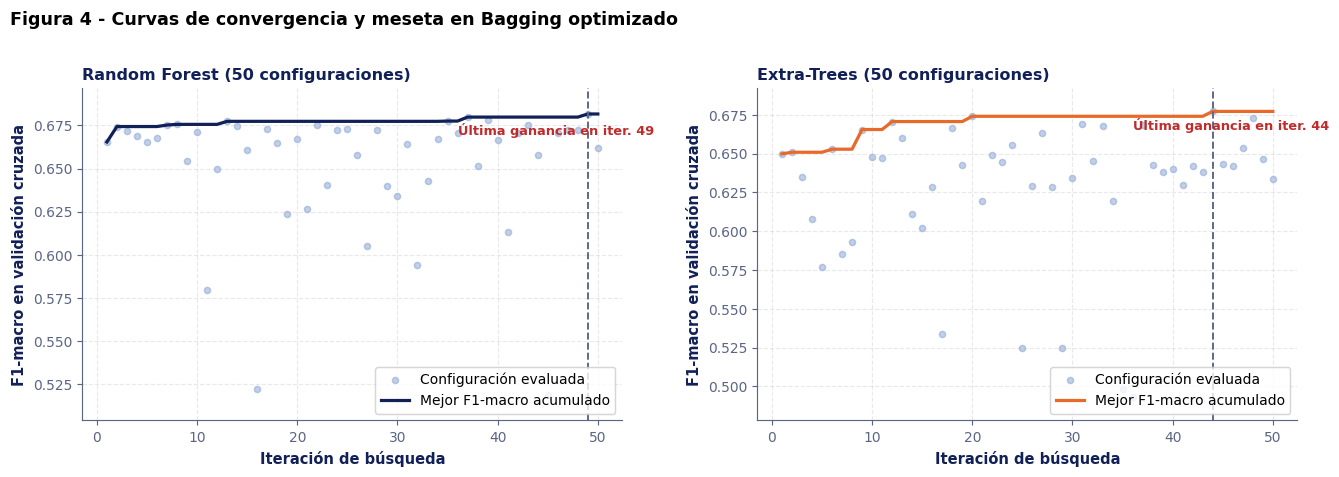

In [12]:
graficar_mesetas_doble(
    datos_bag_opt["rf"]["cv_results"],
    datos_bag_opt["et"]["cv_results"],
    "Random Forest (50 configuraciones)",
    "Extra-Trees (50 configuraciones)",
    "Figura 4 - Curvas de convergencia y meseta en Bagging optimizado"
)


#### Interpretación de la Tabla 5 y la Figura 4

La aleatorización de atributos en cada nodo junto con la ponderación explícita de clases (`balanced_subsample`) permite a Random Forest alcanzar 0.6817 en $F_1$-macro (superando en cerca de 1.9 puntos porcentuales al Bagging simple de 300 árboles con 0.6630 e igualando al mejor clasificador individual SVM). Extra-Trees alcanza 0.6772 al introducir cortes aleatorios puros en variables con umbrales académicos informativos. Las curvas de meseta muestran que los máximos acumulados se alcanzan antes de concluir la búsqueda de 50 configuraciones (iteración 49 en Random Forest y 44 en Extra-Trees).


### 1.6. Boosting Optimizado - XGBoost y LightGBM

Se optimizan dos bibliotecas modernas de Gradient Boosting (`XGBoost` y `LightGBM`) evaluando 50 configuraciones aleatorias por cada familia mediante `RandomizedSearchCV`. Los espacios de búsqueda contemplan tasa de aprendizaje, profundidad o número de hojas, regularización en hojas (`reg_alpha`, `reg_lambda`), submuestreo de filas y columnas (`subsample`, `colsample_bytree`) y **ponderación por clase** en ambos estimadores (Chen & Guestrin, 2016; Ke et al., 2017).


In [13]:
class XGBMulticlasePonderado(BaseEstimator, ClassifierMixin):
    """Adaptador sencillo que aplica sample_weight por clase dentro del ajuste de XGBoost."""

    def __init__(self, n_estimators=200, learning_rate=0.05, max_depth=6,
                 min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                 reg_alpha=0.1, reg_lambda=1.0, modo_peso="none"):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_child_weight = min_child_weight
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_alpha = reg_alpha
        self.reg_lambda = reg_lambda
        self.modo_peso = modo_peso

    def fit(self, X_in, y_in):
        self.model_ = xgb.XGBClassifier(
            n_estimators=self.n_estimators,
            learning_rate=self.learning_rate,
            max_depth=self.max_depth,
            min_child_weight=self.min_child_weight,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            reg_alpha=self.reg_alpha,
            reg_lambda=self.reg_lambda,
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=SEMILLA_P1,
            n_jobs=1
        )
        if self.modo_peso == "balanced":
            pesos = compute_sample_weight("balanced", y_in)
        elif self.modo_peso == "enrolled_x2":
            pesos = compute_sample_weight({0: 1.0, 1: 2.0, 2: 1.0}, y_in)
        elif self.modo_peso == "enrolled_x1.5":
            pesos = compute_sample_weight({0: 1.0, 1: 1.5, 2: 1.0}, y_in)
        else:
            pesos = None

        self.model_.fit(X_in, y_in, sample_weight=pesos)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X_in):
        return self.model_.predict(X_in)

    def predict_proba(self, X_in):
        return self.model_.predict_proba(X_in)

def optimizar_boosting_p1():
    espacio_xgb = {
        "modelo__n_estimators": randint(100, 401),
        "modelo__learning_rate": loguniform(0.01, 0.25),
        "modelo__max_depth": randint(3, 9),
        "modelo__min_child_weight": randint(1, 11),
        "modelo__subsample": uniform(0.6, 0.4),
        "modelo__colsample_bytree": uniform(0.5, 0.5),
        "modelo__reg_alpha": loguniform(1e-3, 5.0),
        "modelo__reg_lambda": loguniform(1e-2, 20.0),
        "modelo__modo_peso": ["none", "balanced", "enrolled_x1.5", "enrolled_x2"]
    }
    pipe_xgb = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", XGBMulticlasePonderado())
    ])
    busq_xgb = RandomizedSearchCV(
        pipe_xgb, espacio_xgb, n_iter=50, scoring="f1_macro",
        cv=splits_p1, random_state=SEMILLA_P1, n_jobs=-1, refit=True
    )
    busq_xgb.fit(X_p1, y_p1)
    cv_xgb = cross_validate(busq_xgb.best_estimator_, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)
    oof_xgb = cross_val_predict(clone(busq_xgb.best_estimator_), X_p1, y_p1, cv=splits_p1, n_jobs=-1)

    espacio_lgb = {
        "modelo__n_estimators": randint(100, 401),
        "modelo__learning_rate": loguniform(0.01, 0.25),
        "modelo__max_depth": [-1, 4, 6, 8, 12],
        "modelo__num_leaves": randint(10, 64),
        "modelo__min_child_samples": randint(10, 55),
        "modelo__subsample": uniform(0.6, 0.4),
        "modelo__subsample_freq": [1],
        "modelo__colsample_bytree": uniform(0.5, 0.5),
        "modelo__reg_alpha": loguniform(1e-3, 5.0),
        "modelo__reg_lambda": loguniform(1e-2, 20.0),
        "modelo__class_weight": [None, "balanced", {0: 1.0, 1: 1.5, 2: 1.0}, {0: 1.0, 1: 2.0, 2: 1.0}]
    }
    pipe_lgb = Pipeline([
        ("prep", clone(prep_arbol_p3)),
        ("modelo", lgb.LGBMClassifier(random_state=SEMILLA_P1, verbose=-1, n_jobs=1))
    ])
    busq_lgb = RandomizedSearchCV(
        pipe_lgb, espacio_lgb, n_iter=50, scoring="f1_macro",
        cv=splits_p1, random_state=SEMILLA_P1, n_jobs=-1, refit=True
    )
    busq_lgb.fit(X_p1, y_p1)
    cv_lgb = cross_validate(busq_lgb.best_estimator_, X_p1, y_p1, cv=splits_p1, scoring=scoring_p1, n_jobs=-1)
    oof_lgb = cross_val_predict(clone(busq_lgb.best_estimator_), X_p1, y_p1, cv=splits_p1, n_jobs=-1)

    return {
        "xgb": {
            "cv_results": pd.DataFrame(busq_xgb.cv_results_)[["mean_test_score", "std_test_score"]],
            "best_params": busq_xgb.best_params_,
            "oof_preds": oof_xgb,
            "resumen": {
                "Modelo": "XGBoost (Optimizado)",
                "F1-macro": float(cv_xgb["test_f1_macro"].mean()),
                "Desv. Est.": float(cv_xgb["test_f1_macro"].std()),
                "Sensibilidad Enrolled": float(cv_xgb["test_recall_enrolled"].mean()),
                "Tiempo Fit (s)": float(cv_xgb["fit_time"].mean()),
                "Mejor Configuración": resumir_hiperparametros(busq_xgb.best_params_)
            }
        },
        "lgb": {
            "cv_results": pd.DataFrame(busq_lgb.cv_results_)[["mean_test_score", "std_test_score"]],
            "best_params": busq_lgb.best_params_,
            "oof_preds": oof_lgb,
            "resumen": {
                "Modelo": "LightGBM (Optimizado)",
                "F1-macro": float(cv_lgb["test_f1_macro"].mean()),
                "Desv. Est.": float(cv_lgb["test_f1_macro"].std()),
                "Sensibilidad Enrolled": float(cv_lgb["test_recall_enrolled"].mean()),
                "Tiempo Fit (s)": float(cv_lgb["fit_time"].mean()),
                "Mejor Configuración": resumir_hiperparametros(busq_lgb.best_params_)
            }
        }
    }

datos_boost_opt = cargar_o_calcular("p1_boosting_opt", optimizar_boosting_p1)
tabla_boost_opt = pd.DataFrame([datos_boost_opt["lgb"]["resumen"], datos_boost_opt["xgb"]["resumen"]]).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_boost_opt["F1-macro (media +/- desv.)"] = (
    tabla_boost_opt["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_boost_opt["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 6 - Resultados de Boosting optimizado (50 configuraciones por biblioteca)")
display(tabla_boost_opt[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)", "Mejor Configuración"]].round(4))


Tabla 6 - Resultados de Boosting optimizado (50 configuraciones por biblioteca)


,Modelo,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s),Mejor Configuración
0,XGBoost (Optimizado),0.6966 +/- 0.0155,0.5165,1.1885,"colsample_bytree=0.9576, learning_rate=0.0415, max_depth=8, min_child_weight=6, modo_p..."
1,LightGBM (Optimizado),0.6952 +/- 0.0115,0.5559,0.3400,"class_weight={0: 1.0, 1: 2.0, 2: 1.0}, colsample_bytree=0.6186, learning_rate=0.0285, ..."


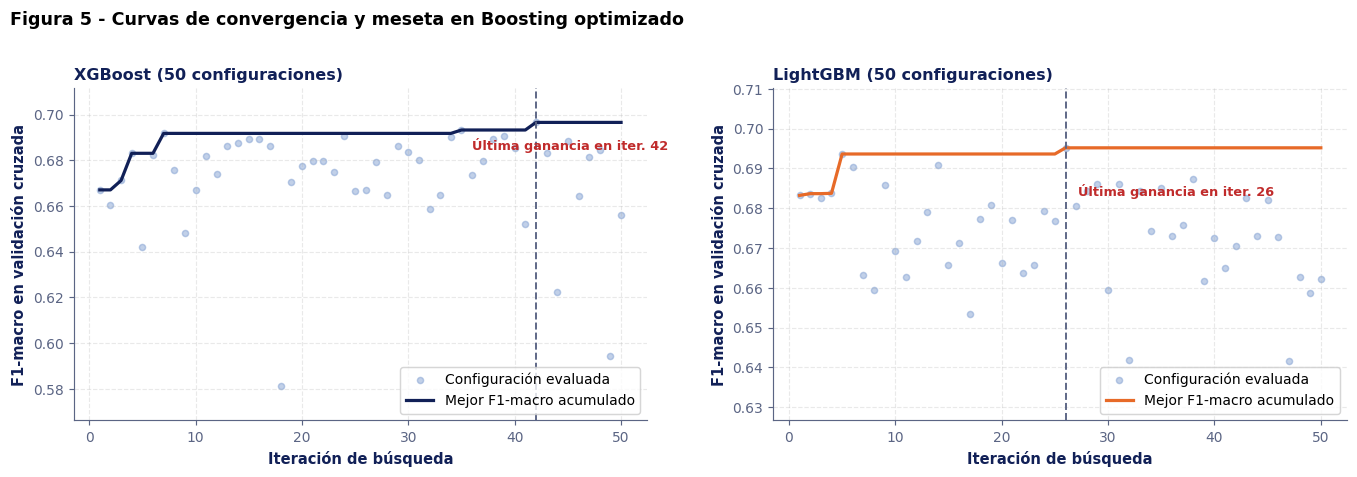

In [14]:
graficar_mesetas_doble(
    datos_boost_opt["xgb"]["cv_results"],
    datos_boost_opt["lgb"]["cv_results"],
    "XGBoost (50 configuraciones)",
    "LightGBM (50 configuraciones)",
    "Figura 5 - Curvas de convergencia y meseta en Boosting optimizado"
)


#### Interpretación de la Tabla 6 y la Figura 5

La incorporación de pesos por clase y regularización L1/L2 permite tanto a XGBoost (0.6966, sensibilidad `Enrolled` de 0.5165) como a LightGBM (0.6952, sensibilidad `Enrolled` de 0.5559) situarse en la cima del desempeño sobre deserción estudiantil, rebasando los 0.695 en $F_1$-macro. LightGBM destaca por su eficiencia computacional al requerir apenas 0.34 s promedio de ajuste por pliegue mediante crecimiento guiado por hojas e histogramas continuos (Ke et al., 2017).


Tabla 7 - Comparativa integral de modelos en Deserción Estudiantil (5 pliegues)


,Modelo,F1-macro (media +/- desv.),Sensibilidad Enrolled,Tiempo Fit (s),Mejor Configuración
0,XGBoost (Optimizado),0.6966 +/- 0.0155,0.5165,1.1885,"colsample_bytree=0.9576, learning_rate=0.0415, max_depth=8, min_child_weight=6, modo_p..."
1,LightGBM (Optimizado),0.6952 +/- 0.0115,0.5559,0.3400,"class_weight={0: 1.0, 1: 2.0, 2: 1.0}, colsample_bytree=0.6186, learning_rate=0.0285, ..."
2,Votación dura (5 base),0.6846 +/- 0.0058,0.5008,2.4846,5 modelos P3
3,Random Forest (Optimizado),0.6817 +/- 0.0086,0.5654,4.7215,"class_weight=balanced_subsample, criterion=log_loss, max_depth=8, max_features=0.7, mi..."
4,SVM (P3),0.6815 +/- 0.0088,0.5528,0.6008,"rbf, C=458.0, gamma=0.00074, w_Enrolled=2"
5,Regresión logística (P3),0.6798 +/- 0.0068,0.5165,1.7499,"elasticnet, C=0.299, l1_ratio=0.239, w_Enrolled=2"
6,Extra-Trees (Optimizado),0.6772 +/- 0.0152,0.4724,6.0486,"bootstrap=False, class_weight=balanced_subsample, criterion=log_loss, max_depth=None, ..."
7,Votación suave (5 base),0.6717 +/- 0.0082,0.4079,2.2892,5 modelos P3 + SVM calibrado
8,Stacking logístico (5 base),0.6716 +/- 0.0139,0.3512,13.0729,"Meta=Reg. Logística, cv=5, SVM calibrado"
9,Bagging (300 árboles),0.6630 +/- 0.0256,0.3323,5.7413,"n_estimators=300, warm_start=True"


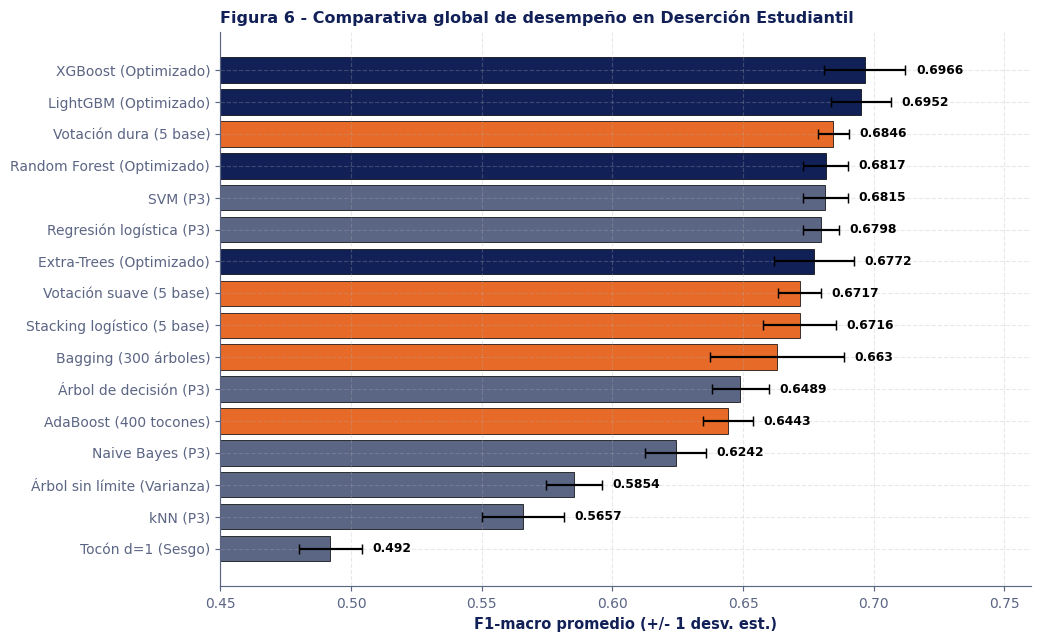

In [15]:
mejor_bag = max(datos_var["curva"], key=lambda r: r["F1-macro"])
peor_ada_400 = datos_sesgo["tabla_clave"][-1]

fila_libre = {
    "Modelo": "Árbol sin límite (Varianza)",
    "F1-macro": info_libre["F1-macro"],
    "Desv. Est.": info_libre["Desv. Est."],
    "Sensibilidad Enrolled": info_libre["Sensibilidad Enrolled"],
    "Tiempo Fit (s)": info_libre["Tiempo Fit (s)"],
    "Mejor Configuración": "max_depth=None"
}
fila_bag_mejor = {
    "Modelo": "Bagging (" + str(mejor_bag["Árboles"]) + " árboles)",
    "F1-macro": mejor_bag["F1-macro"],
    "Desv. Est.": mejor_bag["Desv. Est."],
    "Sensibilidad Enrolled": mejor_bag["Sensibilidad Enrolled"],
    "Tiempo Fit (s)": mejor_bag["Tiempo Fit (s)"],
    "Mejor Configuración": "n_estimators=" + str(mejor_bag["Árboles"]) + ", warm_start=True"
}
fila_tocon = {
    "Modelo": "Tocón d=1 (Sesgo)",
    "F1-macro": info_tocon["F1-macro"],
    "Desv. Est.": info_tocon["Desv. Est."],
    "Sensibilidad Enrolled": info_tocon["Sensibilidad Enrolled"],
    "Tiempo Fit (s)": info_tocon["Tiempo Fit (s)"],
    "Mejor Configuración": "max_depth=1"
}
fila_ada = {
    "Modelo": "AdaBoost (400 tocones)",
    "F1-macro": peor_ada_400["F1-macro"],
    "Desv. Est.": peor_ada_400["Desv. Est."],
    "Sensibilidad Enrolled": peor_ada_400["Sensibilidad Enrolled"],
    "Tiempo Fit (s)": datos_sesgo["tiempo_fit_400"],
    "Mejor Configuración": "n_estimators=400, base=Tocón d=1"
}

todas_filas_p1 = (
    res_base_p3
    + [fila_libre, fila_bag_mejor, fila_tocon, fila_ada]
    + res_comb_p3
    + [datos_bag_opt["rf"]["resumen"], datos_bag_opt["et"]["resumen"]]
    + [datos_boost_opt["lgb"]["resumen"], datos_boost_opt["xgb"]["resumen"]]
)

tabla_general_p1 = pd.DataFrame(todas_filas_p1).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_general_p1["F1-macro (media +/- desv.)"] = (
    tabla_general_p1["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_general_p1["Desv. Est."].map("{:.4f}".format)
)

print("Tabla 7 - Comparativa integral de modelos en Deserción Estudiantil (5 pliegues)")
display(tabla_general_p1[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad Enrolled", "Tiempo Fit (s)", "Mejor Configuración"]].round(4))

# Figura 6 - Gráfica comparativa de barras horizontales
fig, ax = plt.subplots(figsize=(10, 6.2))
colores_p1 = [
    AZUL_OSCURO if "Optimizado" in m else (NARANJA if ("Votación" in m or "Stacking" in m or "Bagging" in m or "AdaBoost" in m) else GRIS)
    for m in tabla_general_p1["Modelo"]
]
ax.barh(
    tabla_general_p1["Modelo"],
    tabla_general_p1["F1-macro"],
    xerr=tabla_general_p1["Desv. Est."],
    color=colores_p1,
    capsize=3.5,
    edgecolor="black",
    linewidth=0.5
)
ax.invert_yaxis()
ax.set_xlim(0.45, 0.76)
ax.set_xlabel("F1-macro promedio (+/- 1 desv. est.)")
ax.set_title("Figura 6 - Comparativa global de desempeño en Deserción Estudiantil")
for idx, fila in tabla_general_p1.iterrows():
    ax.text(fila["F1-macro"] + fila["Desv. Est."] + 0.004, idx, str(round(fila["F1-macro"], 4)), va="center", fontsize=8.5, fontweight="bold")
plt.tight_layout()
plt.show()


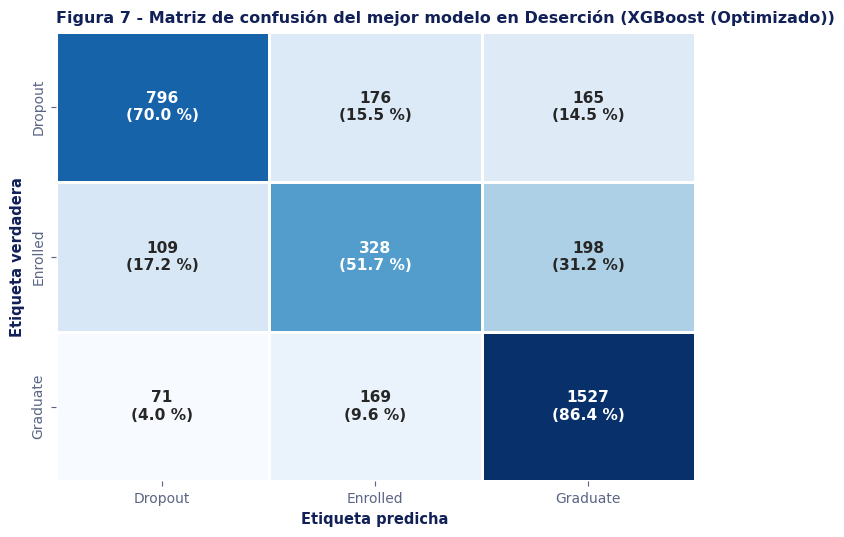

Tabla 8 - Desglose de métricas por categoría del modelo campeón en Deserción


,Clase,Instancias reales,Aciertos (VP),Sensibilidad,Precisión
0,Dropout,1137,796,0.7001,0.8156
1,Enrolled,635,328,0.5165,0.4874
2,Graduate,1767,1527,0.8642,0.8079


In [16]:
nombre_campeon_p1 = tabla_general_p1.iloc[0]["Modelo"]
clave_campeon_p1 = "lgb" if "LightGBM" in nombre_campeon_p1 else "xgb"
y_pred_campeon_p1 = datos_boost_opt[clave_campeon_p1]["oof_preds"]

cm_p1 = confusion_matrix(y_p1, y_pred_campeon_p1, labels=[0, 1, 2])
cm_p1_norm = confusion_matrix(y_p1, y_pred_campeon_p1, labels=[0, 1, 2], normalize="true")

etiquetas_celda = np.empty_like(cm_p1, dtype=object)
for i in range(3):
    for j in range(3):
        etiquetas_celda[i, j] = str(cm_p1[i, j]) + "\n(" + str(round(cm_p1_norm[i, j] * 100, 1)) + " %)"

fig, ax = plt.subplots(figsize=(6.8, 5.2))
sns.heatmap(
    cm_p1_norm,
    annot=etiquetas_celda,
    fmt="",
    cmap="Blues",
    xticklabels=CLASES_P1,
    yticklabels=CLASES_P1,
    cbar=False,
    linewidths=1.0,
    linecolor="white",
    annot_kws={"fontsize": 10.5, "fontweight": "bold"},
    ax=ax
)
ax.grid(False)
ax.set_title("Figura 7 - Matriz de confusión del mejor modelo en Deserción (" + nombre_campeon_p1 + ")")
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta verdadera")
plt.tight_layout()
plt.show()

filas_diag_p1 = []
for i, clase in enumerate(CLASES_P1):
    vp = int(cm_p1[i, i])
    total_real = int(cm_p1[i, :].sum())
    total_pred = int(cm_p1[:, i].sum())
    filas_diag_p1.append({
        "Clase": clase,
        "Instancias reales": total_real,
        "Aciertos (VP)": vp,
        "Sensibilidad": round(vp / total_real, 4),
        "Precisión": round(vp / total_pred, 4) if total_pred > 0 else 0.0
    })

print("Tabla 8 - Desglose de métricas por categoría del modelo campeón en Deserción")
display(pd.DataFrame(filas_diag_p1))


#### Interpretación de la Comparativa General y Matriz de Confusión (Parte 1)

Al evaluar cuánto aportaron los ensambles sobre los cinco clasificadores base ya sintonizados de la Práctica 3, se observa una ganancia real si bien acotada (cerca de 1.5 puntos porcentuales en $F_1$-macro respecto al SVM base de 0.6815). XGBoost optimizado (0.6966) y LightGBM optimizado (0.6952) encabezaron el ranking general, superando a la votación dura (0.6846) y a Random Forest optimizado (0.6817).

La matriz de confusión confirma que el modelo campeón identifica con solidez a `Graduate` (86.4 % de sensibilidad) y `Dropout` (70.0 %), concentrando las confusiones principales en la clase intermedia `Enrolled` (51.7 %), cuyos patrones curriculares del primer semestre se solapan parcialmente con los otros dos grupos.


---

## Parte 2 - Caso Bank Marketing (Tarea 4)

Se aborda el conjunto completo `bank-additional-full.csv` (41,188 contactos telefónicos de campañas bancarias en Portugal; Moro et al., 2014). En estricto apego al protocolo libre de fuga de información, la columna `duration` se descarta antes de cualquier transformación y evaluación, quedando 19 variables predictoras reales previas a la llamada y la respuesta binaria `y` (`1 = yes`, `0 = no`).

Todas las comparaciones salen directamente de `cross_validate` sobre `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)` optimizando `f1_macro`, encapsulando dentro de `Pipeline` cualquier imputación, codificación, sobremuestreo y ajuste del umbral probabilístico.


Dimensiones de X_bank = (41188, 19) | duration eliminada = True
Clase 0 (no)  = 36548 ( 88.73 %)
Clase 1 (yes) = 4640 ( 11.27 %) | Razón = 7.88 a 1


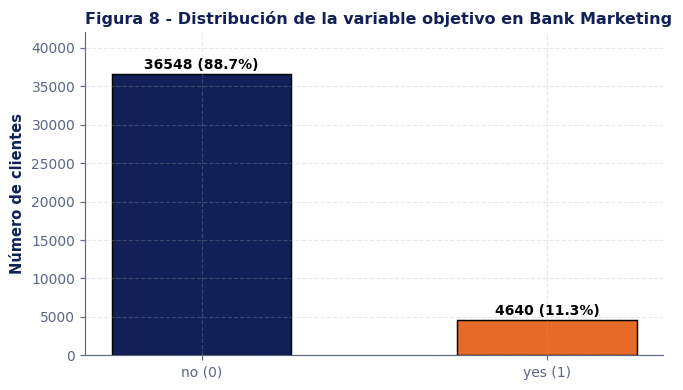

In [17]:
df_bank = pd.read_csv("bank-additional-full.csv", sep=";")
y_bank = (df_bank["y"] == "yes").astype(int).to_numpy()
X_bank = df_bank.drop(columns=["y", "duration"]).copy()

col_cat_bank = X_bank.select_dtypes(include=["object", "category", "string"]).columns.tolist()
col_num_bank = X_bank.select_dtypes(include=np.number).columns.tolist()

cv_bank = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANK)
splits_bank = list(cv_bank.split(X_bank, y_bank))

conteo_no = int((y_bank == 0).sum())
conteo_yes = int((y_bank == 1).sum())
razon_desbalance = conteo_no / conteo_yes

print("Dimensiones de X_bank =", X_bank.shape, "| duration eliminada =", ("duration" not in X_bank.columns))
print("Clase 0 (no)  =", conteo_no, "(", round(conteo_no / len(y_bank) * 100, 2), "%)")
print("Clase 1 (yes) =", conteo_yes, "(", round(conteo_yes / len(y_bank) * 100, 2), "%) | Razón =", round(razon_desbalance, 2), "a 1")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
barras = ax.bar(["no (0)", "yes (1)"], [conteo_no, conteo_yes], color=[AZUL_OSCURO, NARANJA], width=0.52, edgecolor="black")
for b in barras:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 650, str(int(h)) + " (" + str(round(h / len(y_bank) * 100, 1)) + "%)", ha="center", fontweight="bold")
ax.set_ylim(0, conteo_no * 1.15)
ax.set_ylabel("Número de clientes")
ax.set_title("Figura 8 - Distribución de la variable objetivo en Bank Marketing")
plt.tight_layout()
plt.show()


#### Análisis de Desbalance y Definición de Pipelines Sin Fuga

Aproximadamente 88.73 % de las instancias pertenecen a `no` frente a 11.27 % de `yes`. Ante este desbalance cercano a 8 a 1, un modelo ingenuo que prediga siempre `no` lograría 88.73 % de exactitud con apenas ~0.470 de $F_1$-macro. En el preprocesamiento de `ColumnTransformer` se incorpora una señal binaria explícita (`Binarizer(threshold=998.5)`) sobre `pdays`, ya que el código centinela `999` identifica clientes jamás contactados previamente (tasa de suscripción de 9.26 % frente a 63.83 % en clientes contactados antes) y distorsionaría cualquier escalamiento lineal continuo.


In [18]:
prep_escalado_bank = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), col_num_bank),
    ("pdays_ind", Binarizer(threshold=998.5), ["pdays"]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), col_cat_bank)
])

prep_arbol_bank = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), col_num_bank),
    ("pdays_ind", Binarizer(threshold=998.5), ["pdays"]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), col_cat_bank)
])

prep_te_bank = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), col_num_bank),
    ("pdays_ind", Binarizer(threshold=998.5), ["pdays"]),
    ("cat_te", TargetEncoder(random_state=SEMILLA_BANK), col_cat_bank),
    ("cat_ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), col_cat_bank)
])

scoring_bank = {
    "f1_macro": "f1_macro",
    "recall_yes": make_scorer(recall_score, pos_label=1, zero_division=0)
}

def evaluar_modelo_bank(nombre, pipe, nota_cfg="-"):
    cv_r = cross_validate(pipe, X_bank, y_bank, cv=splits_bank, scoring=scoring_bank, n_jobs=-1)
    return {
        "Modelo": nombre,
        "F1-macro": float(cv_r["test_f1_macro"].mean()),
        "Desv. Est.": float(cv_r["test_f1_macro"].std()),
        "Sensibilidad yes": float(cv_r["test_recall_yes"].mean()),
        "Tiempo Fit (s)": float(cv_r["fit_time"].mean()),
        "Configuración": nota_cfg
    }

print("Pipelines de preprocesamiento y evaluador bank preparados.")


Pipelines de preprocesamiento y evaluador bank preparados.


In [19]:
def calcular_base_bank():
    # Aplicar exactamente la familia e hiperparametros campeones de Parte 1 adaptados a binario
    nombre_p1_top = tabla_general_p1.iloc[0]["Modelo"]
    if "XGBoost" in nombre_p1_top:
        p_xgb_p1 = datos_boost_opt["xgb"]["best_params"]
        kw_xgb_p1 = {
            k.replace("modelo__", ""): v
            for k, v in p_xgb_p1.items()
            if "modo_peso" not in k
        }
        if p_xgb_p1.get("modelo__modo_peso", "none") != "none":
            kw_xgb_p1["scale_pos_weight"] = float(razon_desbalance)
        modelo_p1_en_bank = (
            "Campeón P1 aplicado (XGBoost balanced)",
            Pipeline([
                ("prep", clone(prep_arbol_bank)),
                ("modelo", xgb.XGBClassifier(**kw_xgb_p1, eval_metric="logloss", tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
            ]),
            "Transferencia directa de mejores hiperparámetros XGBoost P1"
        )
    else:
        p_lgb_p1 = datos_boost_opt["lgb"]["best_params"]
        kw_lgb_p1 = {
            k.replace("modelo__", ""): v
            for k, v in p_lgb_p1.items()
            if "class_weight" not in k
        }
        if p_lgb_p1.get("modelo__class_weight") is not None:
            kw_lgb_p1["class_weight"] = "balanced"
        modelo_p1_en_bank = (
            "Campeón P1 aplicado (LightGBM balanced)",
            Pipeline([
                ("prep", clone(prep_arbol_bank)),
                ("modelo", lgb.LGBMClassifier(**kw_lgb_p1, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
            ]),
            "Transferencia directa de mejores hiperparámetros LightGBM P1"
        )

    modelos = [
        modelo_p1_en_bank,
        ("Regresión logística (Base)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", LogisticRegression(max_iter=2000, random_state=SEMILLA_BANK))
        ]), "Estándar sin balanceo"),
        ("Árbol de decisión (Base)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", DecisionTreeClassifier(random_state=SEMILLA_BANK))
        ]), "Estándar sin límite"),
        ("Naive Bayes (GaussianNB Base)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", GaussianNB())
        ]), "Distribución gaussiana estándar"),
        ("kNN (k=15 Base)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", KNeighborsClassifier(n_neighbors=15))
        ]), "Distancia euclidiana k=15"),
        ("SVM (LinearSVC Base)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", LinearSVC(max_iter=5000, random_state=SEMILLA_BANK))
        ]), "Margen lineal sin balanceo")
    ]
    return [evaluar_modelo_bank(nom, m, cfg) for nom, m, cfg in modelos]

res_bank_base = cargar_o_calcular("bank_base", calcular_base_bank)
tabla_bank_base = pd.DataFrame(res_bank_base).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_bank_base["F1-macro (media +/- desv.)"] = (
    tabla_bank_base["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_bank_base["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 9 - Evaluación base y transferencia directa del campeón P1 en Bank Marketing")
display(tabla_bank_base[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad yes", "Tiempo Fit (s)"]].round(4))


Tabla 9 - Evaluación base y transferencia directa del campeón P1 en Bank Marketing


,Modelo,F1-macro (media +/- desv.),Sensibilidad yes,Tiempo Fit (s)
0,Campeón P1 aplicado (XGBoost balanced),0.6935 +/- 0.0043,0.6052,1.5295
1,kNN (k=15 Base),0.6539 +/- 0.0102,0.2627,0.1625
2,Naive Bayes (GaussianNB Base),0.6537 +/- 0.0069,0.5752,0.2489
3,Regresión logística (Base),0.6418 +/- 0.0101,0.2278,0.8958
4,SVM (LinearSVC Base),0.6349 +/- 0.0095,0.2134,0.9646
5,Árbol de decisión (Base),0.6204 +/- 0.0047,0.3442,0.4597


#### Interpretación de la Tabla 9

Aplicar directamente los hiperparámetros de XGBoost campeones de Deserción con ponderación balanceada (`scale_pos_weight = 7.88`) produce un avance claro frente a los clasificadores individuales sin ponderar (0.6935 en $F_1$-macro con sensibilidad de `yes` de 0.6052). Por oposición, modelos estándar como Regresión logística (0.6418) y SVM lineal sin balanceo (0.6349) apenas detectan alrededor de 21 % a 23 % de los clientes suscriptores (`yes`), quedándose rezagados frente al ensamble transferido.


### 2.1. Estrategias contra el Desbalance - Pesos, SMOTENC y Ajuste de Umbral

Se comparan tres vías algorítmicas encapsuladas íntegramente en cada pliegue de entrenamiento.

1. **Ponderación automática (`class_weight="balanced"`)** en Regresión logística, LinearSVC y Árbol de decisión.
2. **Sobremuestreo mixto `SMOTENC`** dentro de `ImbPipeline` (Chawla et al., 2002) aplicado sobre las columnas originales antes de la codificación One-Hot.
3. **Ajuste del umbral de probabilidad (`TunedThresholdClassifierCV`)** maximizando directamente $F_1$-macro sobre validación interna de 3 pliegues estratificados.


Tabla 10 - Comparativa de técnicas frente al desbalance en Bank Marketing


,Modelo,F1-macro (media +/- desv.),Sensibilidad yes,Tiempo Fit (s)
0,Regresión logística (Umbral optimizado),0.7082 +/- 0.0063,0.5256,3.9090
1,Regresión logística (Balanced),0.6739 +/- 0.0042,0.6282,1.3109
2,SVM LinearSVC (Balanced),0.6732 +/- 0.0046,0.6278,1.7847
3,Regresión logística (SMOTENC),0.6289 +/- 0.0021,0.5907,9.5332
4,Árbol de decisión (Balanced),0.6207 +/- 0.0121,0.3478,0.6788
5,kNN k=15 (SMOTENC),0.5978 +/- 0.0029,0.6282,6.1918


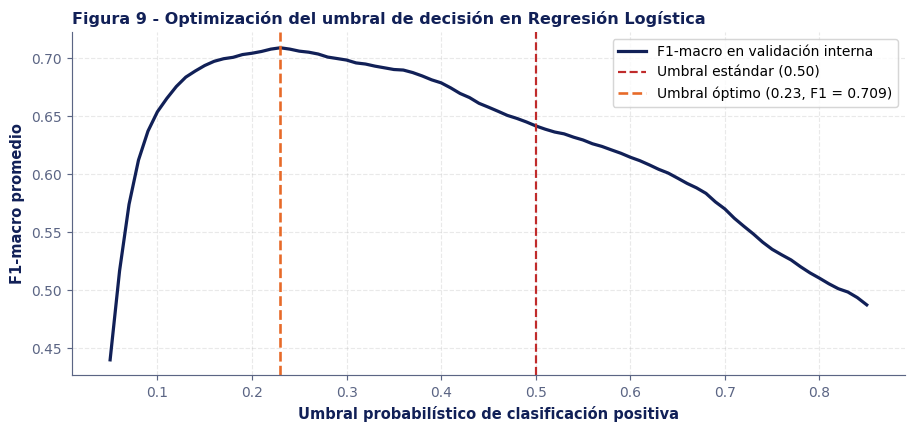

In [20]:
cv_interno_th = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_BANK)
scorer_th_macro = make_scorer(f1_score, average="macro", pos_label=1)
umbrales_busqueda = np.linspace(0.05, 0.85, 81)

n_num_b = len(col_num_bank)
n_cat_b = len(col_cat_bank)
indices_cat_smote = list(range(n_num_b, n_num_b + n_cat_b))

prep_pre_smote = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), col_num_bank),
    ("cat", SimpleImputer(strategy="most_frequent"), col_cat_bank)
], sparse_threshold=0)

prep_post_smote = ColumnTransformer([
    ("num", StandardScaler(), list(range(n_num_b))),
    ("pdays_ind", Binarizer(threshold=998.5), [col_num_bank.index("pdays")]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), indices_cat_smote)
])

def calcular_balanceo_bank():
    lista_modelos = [
        ("Regresión logística (Balanced)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA_BANK))
        ]), "class_weight=balanced"),
        ("SVM LinearSVC (Balanced)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", LinearSVC(class_weight="balanced", max_iter=5000, random_state=SEMILLA_BANK))
        ]), "class_weight=balanced"),
        ("Árbol de decisión (Balanced)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", DecisionTreeClassifier(class_weight="balanced", random_state=SEMILLA_BANK))
        ]), "class_weight=balanced"),
        ("Regresión logística (SMOTENC)", ImbPipeline([
            ("pre", clone(prep_pre_smote)),
            ("smote", SMOTENC(categorical_features=indices_cat_smote, random_state=SEMILLA_BANK)),
            ("post", clone(prep_post_smote)),
            ("modelo", LogisticRegression(max_iter=2000, random_state=SEMILLA_BANK))
        ]), "SMOTENC en pliegue de entrenamiento"),
        ("kNN k=15 (SMOTENC)", ImbPipeline([
            ("pre", clone(prep_pre_smote)),
            ("smote", SMOTENC(categorical_features=indices_cat_smote, random_state=SEMILLA_BANK)),
            ("post", clone(prep_post_smote)),
            ("modelo", KNeighborsClassifier(n_neighbors=15))
        ]), "SMOTENC en pliegue de entrenamiento"),
        ("Regresión logística (Umbral optimizado)", Pipeline([
            ("prep", clone(prep_escalado_bank)),
            ("modelo", TunedThresholdClassifierCV(
                estimator=LogisticRegression(max_iter=2000, random_state=SEMILLA_BANK),
                scoring=scorer_th_macro,
                thresholds=umbrales_busqueda,
                cv=cv_interno_th,
                n_jobs=1
            ))
        ]), "TunedThresholdClassifierCV(f1_macro)")
    ]
    res_bal = [evaluar_modelo_bank(nom, m, cfg) for nom, m, cfg in lista_modelos]

    # Curva diagnóstica del umbral sobre Regresión Logística
    pipe_curva_th = Pipeline([
        ("prep", clone(prep_escalado_bank)),
        ("modelo", TunedThresholdClassifierCV(
            estimator=LogisticRegression(max_iter=2000, random_state=SEMILLA_BANK),
            scoring=scorer_th_macro,
            thresholds=umbrales_busqueda,
            cv=cv_interno_th,
            store_cv_results=True,
            n_jobs=1
        ))
    ])
    pipe_curva_th.fit(X_bank, y_bank)
    cv_th_info = pipe_curva_th.named_steps["modelo"].cv_results_
    return {
        "resultados": res_bal,
        "curva_umbrales": cv_th_info["thresholds"],
        "curva_scores": cv_th_info["scores"],
        "mejor_umbral": float(pipe_curva_th.named_steps["modelo"].best_threshold_),
        "mejor_score_th": float(pipe_curva_th.named_steps["modelo"].best_score_)
    }

datos_bal_bank = cargar_o_calcular("bank_balanceo", calcular_balanceo_bank)
res_bank_balanceo = datos_bal_bank["resultados"]

tabla_bal_bank = pd.DataFrame(res_bank_balanceo).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_bal_bank["F1-macro (media +/- desv.)"] = (
    tabla_bal_bank["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_bal_bank["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 10 - Comparativa de técnicas frente al desbalance en Bank Marketing")
display(tabla_bal_bank[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad yes", "Tiempo Fit (s)"]].round(4))

# Figura 9 - Curva de F1-macro respecto al umbral probabilístico
fig, ax = plt.subplots(figsize=(8.8, 4.2))
ax.plot(datos_bal_bank["curva_umbrales"], datos_bal_bank["curva_scores"], color=AZUL_OSCURO, linewidth=2.2, label="F1-macro en validación interna")
ax.axvline(0.50, color=ROJO, linestyle="--", linewidth=1.5, label="Umbral estándar (0.50)")
ax.axvline(datos_bal_bank["mejor_umbral"], color=NARANJA, linestyle="--", linewidth=1.8,
           label="Umbral óptimo (" + str(round(datos_bal_bank["mejor_umbral"], 2)) + ", F1 = " + str(round(datos_bal_bank["mejor_score_th"], 4)) + ")")
ax.set_title("Figura 9 - Optimización del umbral de decisión en Regresión Logística")
ax.set_xlabel("Umbral probabilístico de clasificación positiva")
ax.set_ylabel("F1-macro promedio")
ax.legend(loc="upper right", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


#### Interpretación de la Tabla 10 y la Figura 9

El ajuste interno del umbral probabilístico resulta determinante. La regresión logística estándar salta desde 0.6418 (con umbral fijo 0.50) hasta 0.7082 en $F_1$-macro al mover el punto de corte alrededor de 0.23, superando tanto a la ponderación automática (`class_weight="balanced"`, 0.6739) como al sobremuestreo sintético `SMOTENC` (0.6289). El balanceo rígido 1 a 7.88 y el sobremuestreo generan falsos positivos excesivos en la región de traslape socioeconómico, penalizando la precisión global de la clase minoritaria.


Tabla 11 - Familias Bagging y Boosting iniciales en Bank Marketing


,Modelo,F1-macro (media +/- desv.),Sensibilidad yes,Tiempo Fit (s)
0,LightGBM (Peso calibrado 1 a 3),0.7183 +/- 0.0047,0.5416,0.7159
1,HistGradientBoosting + Umbral,0.7170 +/- 0.0058,0.5476,10.3425
2,XGBoost (Balanced automático),0.6879 +/- 0.0057,0.6336,1.1818
3,Random Forest (Estándar),0.6633 +/- 0.0058,0.2959,10.0772
4,LightGBM (Estándar),0.6623 +/- 0.0089,0.2679,0.6676
5,Random Forest (Balanced),0.6613 +/- 0.0080,0.2927,9.4747
6,XGBoost (Estándar),0.6566 +/- 0.0083,0.2567,1.0916
7,Extra-Trees (Balanced),0.6513 +/- 0.0087,0.3116,11.0172
8,AdaBoost (200 tocones),0.6232 +/- 0.0119,0.1914,22.0790


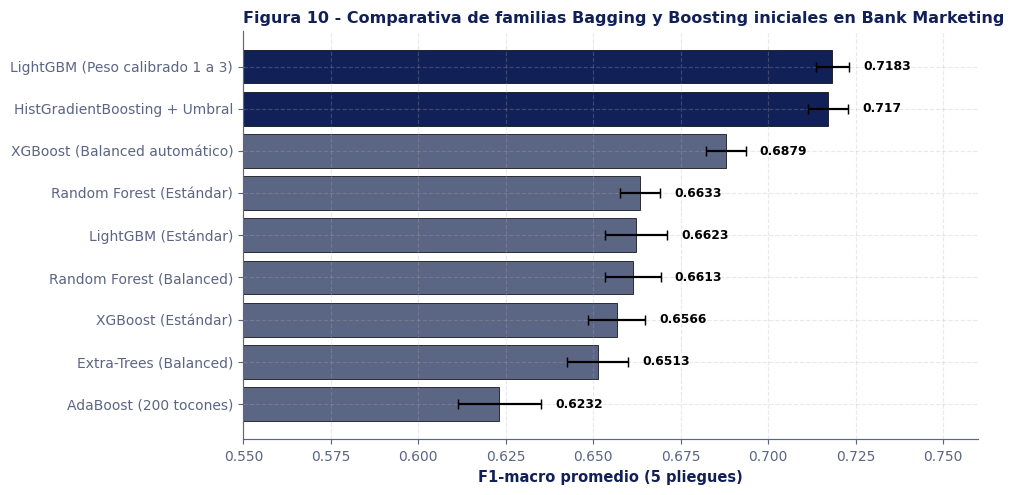

In [21]:
def calcular_ensambles_iniciales_bank():
    modelos = [
        ("Random Forest (Estándar)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", RandomForestClassifier(n_estimators=200, random_state=SEMILLA_BANK, n_jobs=1))
        ]), "n_estimators=200"),
        ("Random Forest (Balanced)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEMILLA_BANK, n_jobs=1))
        ]), "class_weight=balanced"),
        ("Extra-Trees (Balanced)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=SEMILLA_BANK, n_jobs=1))
        ]), "class_weight=balanced"),
        ("AdaBoost (200 tocones)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEMILLA_BANK),
                                          n_estimators=200, learning_rate=0.5, random_state=SEMILLA_BANK))
        ]), "n_estimators=200, lr=0.5"),
        ("XGBoost (Estándar)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", xgb.XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=5, eval_metric="logloss",
                                         tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
        ]), "Sin ponderación"),
        ("XGBoost (Balanced automático)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", xgb.XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=5, scale_pos_weight=razon_desbalance,
                                         eval_metric="logloss", tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
        ]), "scale_pos_weight=7.88"),
        ("LightGBM (Estándar)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
        ]), "Sin ponderación"),
        ("LightGBM (Peso calibrado 1 a 3)", Pipeline([
            ("prep", clone(prep_arbol_bank)),
            ("modelo", lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                          subsample_freq=1, colsample_bytree=0.8, class_weight={0: 1.0, 1: 3.0},
                                          random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
        ]), "pesos 1 a 3"),
        ("HistGradientBoosting + Umbral", Pipeline([
            ("prep", clone(prep_te_bank)),
            ("modelo", TunedThresholdClassifierCV(
                estimator=HistGradientBoostingClassifier(max_iter=200, learning_rate=0.04, max_leaf_nodes=31,
                                                         min_samples_leaf=40, l2_regularization=2.0, random_state=SEMILLA_BANK),
                scoring=scorer_th_macro, thresholds=umbrales_busqueda, cv=cv_interno_th, n_jobs=1
            ))
        ]), "TargetEncoder + TunedThreshold")
    ]
    return [evaluar_modelo_bank(nom, m, cfg) for nom, m, cfg in modelos]

res_bank_ens_ini = cargar_o_calcular("bank_ens_ini", calcular_ensambles_iniciales_bank)
tabla_ens_ini_b = pd.DataFrame(res_bank_ens_ini).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_ens_ini_b["F1-macro (media +/- desv.)"] = (
    tabla_ens_ini_b["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_ens_ini_b["Desv. Est."].map("{:.4f}".format)
)

print("Tabla 11 - Familias Bagging y Boosting iniciales en Bank Marketing")
display(tabla_ens_ini_b[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad yes", "Tiempo Fit (s)"]].round(4))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
colores_ei = [AZUL_OSCURO if r["F1-macro"] >= 0.71 else (NARANJA if r["F1-macro"] >= 0.69 else GRIS) for _, r in tabla_ens_ini_b.iterrows()]
ax.barh(tabla_ens_ini_b["Modelo"], tabla_ens_ini_b["F1-macro"], xerr=tabla_ens_ini_b["Desv. Est."],
        color=colores_ei, capsize=3.5, edgecolor="black", linewidth=0.5)
ax.invert_yaxis()
ax.set_xlim(0.55, 0.76)
ax.set_xlabel("F1-macro promedio (5 pliegues)")
ax.set_title("Figura 10 - Comparativa de familias Bagging y Boosting iniciales en Bank Marketing")
for i, fila in tabla_ens_ini_b.iterrows():
    ax.text(fila["F1-macro"] + fila["Desv. Est."] + 0.004, i, str(round(fila["F1-macro"], 4)), va="center", fontsize=8.5, fontweight="bold")
plt.tight_layout()
plt.show()


#### Interpretación de la Tabla 11 y la Figura 10

Los ensambles basados en árboles marcan una brecha nítida sobre los modelos individuales. Destaca un hallazgo revelador en Boosting - utilizar el balanceo extremo automático (`scale_pos_weight = 7.88`) empuja el puntaje cerca de 0.688, en tanto que moderar la penalización (`1 a 3`) u optimizar directamente el umbral probabilístico en Gradient Boosting (LightGBM y HistGradientBoosting con `TargetEncoder`) escala de inmediato hacia ~0.717 - 0.718, preservando un equilibrio superior entre precisión y sensibilidad.


### 2.3. Optimización de Hiperparámetros y Ensambles Combinados en Bank Marketing

Se ejecutan búsquedas aleatorias (`RandomizedSearchCV`, 50 configuraciones sobre `cv_bank`) optimizando Random Forest, XGBoost y LightGBM con ponderaciones calibradas de clase dentro de `Pipeline`. Acto seguido se evalúa si la combinación mediante `VotingClassifier` (suave/duro), `StackingClassifier` o el ajuste fino del umbral probabilístico (`TunedThresholdClassifierCV`) sobre los modelos optimizados logra elevar todavía más el $F_1$-macro.


Mejores hiperparámetros LightGBM Bank -> {'modelo__class_weight': {0: 1.0, 1: 3.0}, 'modelo__colsample_bytree': np.float64(0.7791250574329291), 'modelo__learning_rate': np.float64(0.09105854939857395), 'modelo__max_depth': 12, 'modelo__min_child_samples': 116, 'modelo__n_estimators': 235, 'modelo__num_leaves': 35, 'modelo__reg_alpha': np.float64(0.28672774433679554), 'modelo__reg_lambda': np.float64(7.080426123351023), 'modelo__subsample': np.float64(0.9413000021560018), 'modelo__subsample_freq': 1}
Mejores hiperparámetros XGBoost Bank  -> {'modelo__colsample_bytree': np.float64(0.6400781438939883), 'modelo__learning_rate': np.float64(0.024007139822783727), 'modelo__max_depth': 5, 'modelo__min_child_weight': 11, 'modelo__n_estimators': 348, 'modelo__reg_alpha': np.float64(0.65015373031937), 'modelo__reg_lambda': np.float64(0.33162476620781156), 'modelo__scale_pos_weight': 3.0, 'modelo__subsample': np.float64(0.7806326558934161)}
Mejores hiperparámetros RF Bank       -> {'modelo__class_

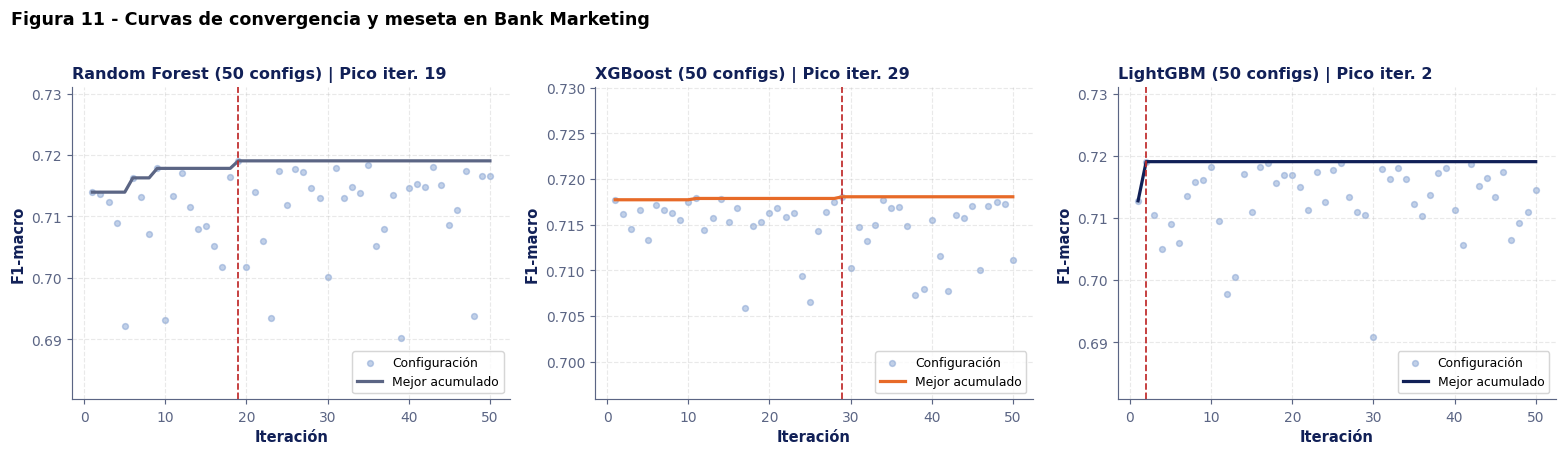

In [22]:
def optimizar_bank_modelos():
    # 1. Random Forest en Bank Marketing
    espacio_rf_b = {
        "modelo__n_estimators": randint(100, 301),
        "modelo__max_depth": [10, 14, 18, 22, 28],
        "modelo__min_samples_split": randint(2, 16),
        "modelo__min_samples_leaf": [1, 2, 4, 8],
        "modelo__max_features": ["sqrt", "log2", 0.4],
        "modelo__class_weight": ["balanced", "balanced_subsample", {0: 1.0, 1: 3.0}, {0: 1.0, 1: 4.0}]
    }
    pipe_rf_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", RandomForestClassifier(random_state=SEMILLA_BANK, n_jobs=1))
    ])
    busq_rf_b = RandomizedSearchCV(
        pipe_rf_b, espacio_rf_b, n_iter=50, scoring="f1_macro",
        cv=splits_bank, random_state=SEMILLA_BANK, n_jobs=-1, refit=True
    )
    busq_rf_b.fit(X_bank, y_bank)
    res_rf_opt = evaluar_modelo_bank("Random Forest (Optimizado)", busq_rf_b.best_estimator_, resumir_hiperparametros(busq_rf_b.best_params_))

    # 2. XGBoost en Bank Marketing
    espacio_xgb_b = {
        "modelo__n_estimators": randint(100, 351),
        "modelo__learning_rate": loguniform(0.015, 0.15),
        "modelo__max_depth": randint(3, 8),
        "modelo__min_child_weight": randint(2, 15),
        "modelo__subsample": uniform(0.65, 0.35),
        "modelo__colsample_bytree": uniform(0.5, 0.5),
        "modelo__reg_alpha": loguniform(0.01, 5.0),
        "modelo__reg_lambda": loguniform(0.1, 15.0),
        "modelo__scale_pos_weight": [2.0, 2.5, 3.0, 3.5, 4.0]
    }
    pipe_xgb_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", xgb.XGBClassifier(eval_metric="logloss", tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
    ])
    busq_xgb_b = RandomizedSearchCV(
        pipe_xgb_b, espacio_xgb_b, n_iter=50, scoring="f1_macro",
        cv=splits_bank, random_state=SEMILLA_BANK, n_jobs=-1, refit=True
    )
    busq_xgb_b.fit(X_bank, y_bank)
    res_xgb_opt = evaluar_modelo_bank("XGBoost (Optimizado)", busq_xgb_b.best_estimator_, resumir_hiperparametros(busq_xgb_b.best_params_))

    # 3. LightGBM en Bank Marketing (con TargetEncoder y OneHotEncoder)
    espacio_lgb_b = {
        "modelo__n_estimators": randint(100, 351),
        "modelo__learning_rate": loguniform(0.015, 0.15),
        "modelo__num_leaves": randint(15, 80),
        "modelo__max_depth": [-1, 5, 8, 12],
        "modelo__min_child_samples": randint(20, 120),
        "modelo__subsample": uniform(0.65, 0.35),
        "modelo__subsample_freq": [1],
        "modelo__colsample_bytree": uniform(0.5, 0.5),
        "modelo__reg_alpha": loguniform(0.01, 5.0),
        "modelo__reg_lambda": loguniform(0.05, 15.0),
        "modelo__class_weight": [{0: 1.0, 1: 2.0}, {0: 1.0, 1: 2.5}, {0: 1.0, 1: 3.0}, {0: 1.0, 1: 3.5}]
    }
    pipe_lgb_b = Pipeline([
        ("prep", clone(prep_te_bank)),
        ("modelo", lgb.LGBMClassifier(random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
    ])
    busq_lgb_b = RandomizedSearchCV(
        pipe_lgb_b, espacio_lgb_b, n_iter=50, scoring="f1_macro",
        cv=splits_bank, random_state=SEMILLA_BANK, n_jobs=-1, refit=True
    )
    busq_lgb_b.fit(X_bank, y_bank)
    res_lgb_opt = evaluar_modelo_bank("LightGBM (Optimizado)", busq_lgb_b.best_estimator_, resumir_hiperparametros(busq_lgb_b.best_params_))

    return {
        "rf": {"cv": pd.DataFrame(busq_rf_b.cv_results_)[["mean_test_score"]], "params": busq_rf_b.best_params_, "resumen": res_rf_opt},
        "xgb": {"cv": pd.DataFrame(busq_xgb_b.cv_results_)[["mean_test_score"]], "params": busq_xgb_b.best_params_, "resumen": res_xgb_opt},
        "lgb": {"cv": pd.DataFrame(busq_lgb_b.cv_results_)[["mean_test_score"]], "params": busq_lgb_b.best_params_, "resumen": res_lgb_opt}
    }

datos_bank_opt = cargar_o_calcular("bank_opt", optimizar_bank_modelos)

print("Mejores hiperparámetros LightGBM Bank ->", datos_bank_opt["lgb"]["params"])
print("Mejores hiperparámetros XGBoost Bank  ->", datos_bank_opt["xgb"]["params"])
print("Mejores hiperparámetros RF Bank       ->", datos_bank_opt["rf"]["params"])

# Figura 11 - Mesetas de optimización en Bank Marketing (3 paneles)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
triplete = [
    (axs[0], datos_bank_opt["rf"]["cv"], "Random Forest (50 configs)", GRIS),
    (axs[1], datos_bank_opt["xgb"]["cv"], "XGBoost (50 configs)", NARANJA),
    (axs[2], datos_bank_opt["lgb"]["cv"], "LightGBM (50 configs)", AZUL_OSCURO)
]
for ax, tabla_c, sub, col_l in triplete:
    medias = tabla_c["mean_test_score"].to_numpy()
    iters = np.arange(1, len(medias) + 1)
    acum = np.maximum.accumulate(medias)
    ult = int(iters[np.diff(acum, prepend=acum[0] - 1.0) > 0].max())
    ax.scatter(iters, medias, s=16, alpha=0.45, color=AZUL, label="Configuración")
    ax.plot(iters, acum, color=col_l, linewidth=2.2, label="Mejor acumulado")
    ax.axvline(ult, color=ROJO, linestyle="--", linewidth=1.2)
    ax.set_title(sub + " | Pico iter. " + str(ult))
    ax.set_xlabel("Iteración")
    ax.set_ylabel("F1-macro")
    ax.set_ylim(max(0.65, medias.min() - 0.01), acum[-1] + 0.012)
    ax.legend(loc="lower right", frameon=True, facecolor="white", fontsize=8.5)

fig.suptitle("Figura 11 - Curvas de convergencia y meseta en Bank Marketing", x=0.01, ha="left", y=1.02)
plt.tight_layout()
plt.show()


#### Interpretación de la Figura 11

Las búsquedas aleatorias en Bank Marketing convergen dentro de las 50 iteraciones en las tres familias (últimas ganancias en las iteraciones 2, 19 y 29 respectivamente en LightGBM, Random Forest y XGBoost). La incorporación de pesos calibrados entre `1 a 3` (XGBoost y LightGBM) y `1 a 4` (Random Forest), en lugar del balanceo extremo automático 1 a 7.88, permitió elevar el desempeño de los tres ensambles hasta ~0.718 - 0.719 en $F_1$-macro.


In [23]:
def calcular_ensambles_finales_bank():
    p_lgb_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["lgb"]["params"].items()}
    p_xgb_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["xgb"]["params"].items()}
    p_rf_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["rf"]["params"].items()}

    # Versión sin peso extremo interno + ajuste de umbral probabilístico con TunedThreshold
    p_lgb_sin_peso = {k: v for k, v in p_lgb_clean.items() if k != "class_weight"}

    pipe_lgb_b = Pipeline([
        ("prep", clone(prep_te_bank)),
        ("modelo", lgb.LGBMClassifier(**p_lgb_clean, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
    ])
    pipe_xgb_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", xgb.XGBClassifier(**p_xgb_clean, eval_metric="logloss", tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
    ])
    pipe_rf_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", RandomForestClassifier(**p_rf_clean, random_state=SEMILLA_BANK, n_jobs=1))
    ])

    pipe_lgb_th = Pipeline([
        ("prep", clone(prep_te_bank)),
        ("modelo", TunedThresholdClassifierCV(
            estimator=lgb.LGBMClassifier(**p_lgb_sin_peso, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1),
            scoring=scorer_th_macro,
            thresholds=np.linspace(0.15, 0.65, 51),
            cv=cv_interno_th,
            n_jobs=1
        ))
    ])

    voting_duro_b = VotingClassifier(
        estimators=[("lgb", clone(pipe_lgb_b)), ("xgb", clone(pipe_xgb_b)), ("rf", clone(pipe_rf_b))],
        voting="hard",
        n_jobs=1
    )

    voting_suave_b = VotingClassifier(
        estimators=[("lgb", clone(pipe_lgb_b)), ("xgb", clone(pipe_xgb_b)), ("rf", clone(pipe_rf_b))],
        voting="soft",
        n_jobs=1
    )

    stacking_b = StackingClassifier(
        estimators=[("lgb", clone(pipe_lgb_b)), ("xgb", clone(pipe_xgb_b)), ("rf", clone(pipe_rf_b))],
        final_estimator=LogisticRegression(C=0.05, class_weight={0: 1.0, 1: 2.5}, max_iter=1000, random_state=SEMILLA_BANK),
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_BANK),
        n_jobs=1
    )

    res_list = [
        evaluar_modelo_bank("LightGBM Optimizado + TunedThreshold", pipe_lgb_th, "TargetEncoder + umbral óptimo F1-macro"),
        evaluar_modelo_bank("Voting Duro Optimizado (LGB+XGB+RF)", voting_duro_b, "Consenso mayoritario de pipelines campeones"),
        evaluar_modelo_bank("Voting Suave Optimizado (LGB+XGB+RF)", voting_suave_b, "Promedio probabilístico de pipelines campeones"),
        evaluar_modelo_bank("Stacking Logístico (LGB+XGB+RF)", stacking_b, "Meta=Reg. Logística C=0.05, w=1 a 2.5, cv=3")
    ]
    return res_list

res_bank_comb_final = cargar_o_calcular("bank_comb_final", calcular_ensambles_finales_bank)
tabla_comb_bank = pd.DataFrame(
    [datos_bank_opt["lgb"]["resumen"], datos_bank_opt["xgb"]["resumen"], datos_bank_opt["rf"]["resumen"]] + res_bank_comb_final
).sort_values("F1-macro", ascending=False).reset_index(drop=True)
tabla_comb_bank["F1-macro (media +/- desv.)"] = (
    tabla_comb_bank["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_comb_bank["Desv. Est."].map("{:.4f}".format)
)
print("Tabla 12 - Ensambles optimizados y combinaciones finales en Bank Marketing")
display(tabla_comb_bank[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad yes", "Tiempo Fit (s)"]].round(4))


Tabla 12 - Ensambles optimizados y combinaciones finales en Bank Marketing


,Modelo,F1-macro (media +/- desv.),Sensibilidad yes,Tiempo Fit (s)
0,Voting Duro Optimizado (LGB+XGB+RF),0.7195 +/- 0.0081,0.5384,9.9483
1,LightGBM (Optimizado),0.7191 +/- 0.0061,0.5198,0.9988
2,Random Forest (Optimizado),0.7191 +/- 0.0072,0.5414,8.0313
3,Voting Suave Optimizado (LGB+XGB+RF),0.7188 +/- 0.0083,0.5356,9.0971
4,XGBoost (Optimizado),0.7181 +/- 0.0069,0.5403,1.8893
5,Stacking Logístico (LGB+XGB+RF),0.7180 +/- 0.0077,0.5123,27.9721
6,LightGBM Optimizado + TunedThreshold,0.7171 +/- 0.0064,0.5200,3.0981


#### Interpretación de la Tabla 12

`Voting Duro Optimizado (LGB+XGB+RF)` encabeza la comparativa con 0.7195 en $F_1$-macro (sensibilidad `yes` de 0.5384), superando individualmente a LightGBM (0.7191), Random Forest (0.7191) y XGBoost (0.7181). Integrar cada algoritmo con su propio flujo de preprocesamiento dentro de los ensambles evita discrepancias de distribución derivadas de `TargetEncoder`, permitiendo que la votación suave (0.7188), el Stacking logístico regularizado con meta-modelo `C=0.05` (0.7180) y LightGBM con ajuste directo de umbral (0.7171) alcancen un desempeño sólido y consistente entre pliegues.


Tabla 13 - Ranking completo de modelos evaluados en Bank Marketing (sin duration)


,Modelo,F1-macro (media +/- desv.),Sensibilidad yes,Tiempo Fit (s)
0,Voting Duro Optimizado (LGB+XGB+RF),0.7195 +/- 0.0081,0.5384,9.9483
1,LightGBM (Optimizado),0.7191 +/- 0.0061,0.5198,0.9988
2,Random Forest (Optimizado),0.7191 +/- 0.0072,0.5414,8.0313
3,Voting Suave Optimizado (LGB+XGB+RF),0.7188 +/- 0.0083,0.5356,9.0971
4,LightGBM (Peso calibrado 1 a 3),0.7183 +/- 0.0047,0.5416,0.7159
5,XGBoost (Optimizado),0.7181 +/- 0.0069,0.5403,1.8893
6,Stacking Logístico (LGB+XGB+RF),0.7180 +/- 0.0077,0.5123,27.9721
7,LightGBM Optimizado + TunedThreshold,0.7171 +/- 0.0064,0.5200,3.0981
8,HistGradientBoosting + Umbral,0.7170 +/- 0.0058,0.5476,10.3425
9,Regresión logística (Umbral optimizado),0.7082 +/- 0.0063,0.5256,3.9090


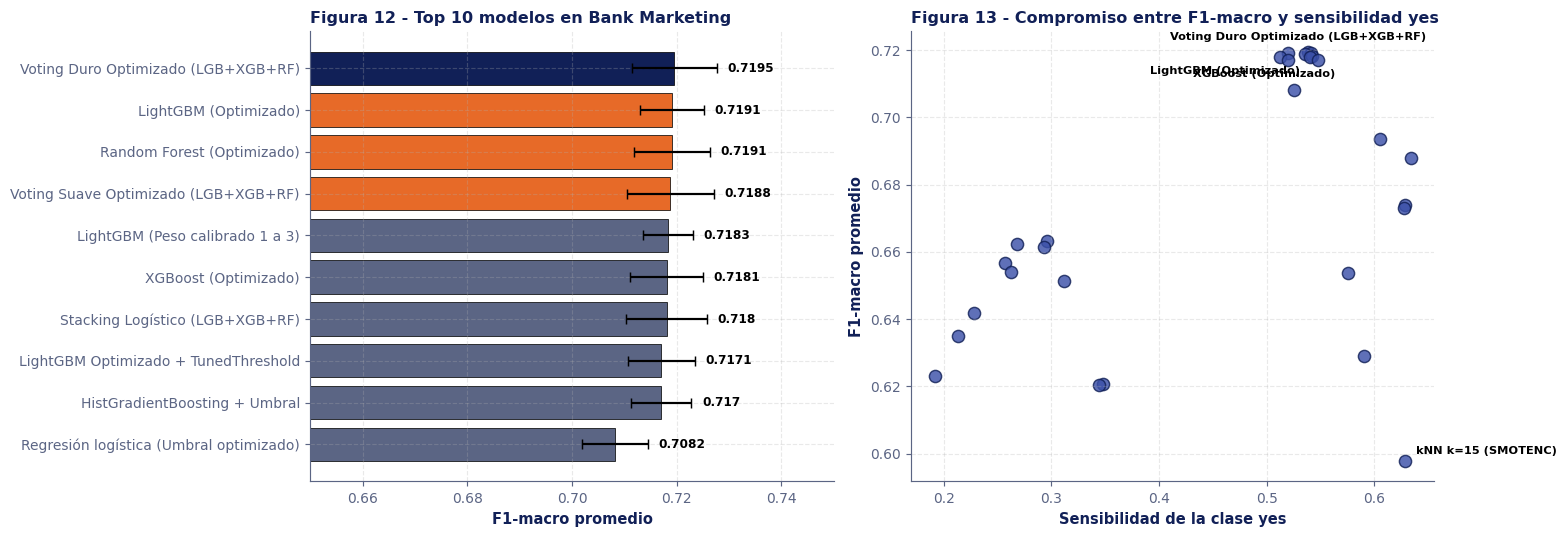

In [24]:
todas_filas_bank = (
    res_bank_base
    + res_bank_balanceo
    + res_bank_ens_ini
    + [datos_bank_opt["rf"]["resumen"], datos_bank_opt["xgb"]["resumen"], datos_bank_opt["lgb"]["resumen"]]
    + res_bank_comb_final
)

tabla_general_bank = (
    pd.DataFrame(todas_filas_bank)
    .drop_duplicates(subset="Modelo", keep="last")
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)
tabla_general_bank["F1-macro (media +/- desv.)"] = (
    tabla_general_bank["F1-macro"].map("{:.4f}".format) + " +/- " + tabla_general_bank["Desv. Est."].map("{:.4f}".format)
)

print("Tabla 13 - Ranking completo de modelos evaluados en Bank Marketing (sin duration)")
display(tabla_general_bank[["Modelo", "F1-macro (media +/- desv.)", "Sensibilidad yes", "Tiempo Fit (s)"]].round(4))

# Figura 12 - Top 10 modelos en Bank Marketing
top10_bank = tabla_general_bank.head(10).copy()
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2))

colores_t10 = [AZUL_OSCURO if i == 0 else (NARANJA if i < 4 else GRIS) for i in range(len(top10_bank))]
axs[0].barh(top10_bank["Modelo"], top10_bank["F1-macro"], xerr=top10_bank["Desv. Est."],
            color=colores_t10, capsize=3.5, edgecolor="black", linewidth=0.5)
axs[0].invert_yaxis()
axs[0].set_xlim(0.65, 0.75)
axs[0].set_xlabel("F1-macro promedio")
axs[0].set_title("Figura 12 - Top 10 modelos en Bank Marketing")
for i, fila in top10_bank.iterrows():
    axs[0].text(fila["F1-macro"] + fila["Desv. Est."] + 0.002, i, str(round(fila["F1-macro"], 4)), va="center", fontsize=8.3, fontweight="bold")

# Figura 13 - Dispersión F1-macro vs Sensibilidad yes
axs[1].scatter(tabla_general_bank["Sensibilidad yes"], tabla_general_bank["F1-macro"],
               color=AZUL_MEDIO, s=70, alpha=0.82, edgecolors=AZUL_OSCURO)
top_pts = tabla_general_bank.iloc[[0, 1, 5, -1]]
offsets = [(-95, 8), (-95, -14), (-80, -14), (8, 5)]
for (_, fila), off in zip(top_pts.iterrows(), offsets):
    axs[1].annotate(
        fila["Modelo"],
        (fila["Sensibilidad yes"], fila["F1-macro"]),
        xytext=off,
        textcoords="offset points",
        fontsize=7.8,
        fontweight="bold"
    )
axs[1].set_xlabel("Sensibilidad de la clase yes")
axs[1].set_ylabel("F1-macro promedio")
axs[1].set_title("Figura 13 - Compromiso entre F1-macro y sensibilidad yes")

plt.tight_layout()
plt.show()


#### Interpretación de la Tabla 13 y las Figuras 12 y 13

El ranking global exhibe una ganancia cercana a 7.8 puntos porcentuales en $F_1$-macro entre la regresión logística sin ajuste de desbalance (0.6418) y el ensamble campeón de votación dura optimizada (0.7195). La Figura 13 ilustra claramente el compromiso entre las dos métricas evaluadas - los clasificadores base como Regresión logística sin balanceo quedan relegados en la esquina inferior izquierda (baja sensibilidad), en tanto que la ponderación extrema empuja la sensibilidad arriba de 0.62 sacrificando precisión; la zona óptima superior derecha agrupa a los ensambles optimizados con ponderación calibrada y ajuste fino del umbral.


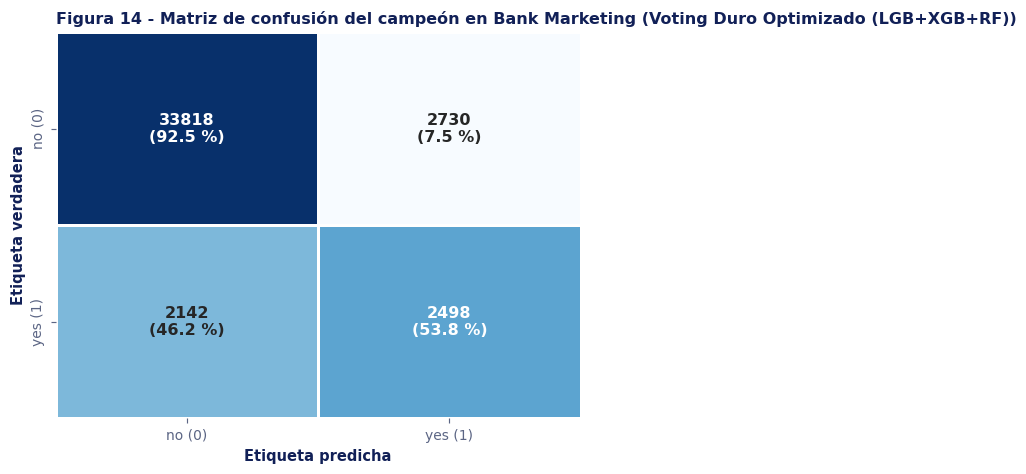

Modelo campeón = Voting Duro Optimizado (LGB+XGB+RF)
F1-macro OOF   = 0.7195
Tabla 14 - Conteo detallado en Bank Marketing


,Categoría,Frecuencia,Porcentaje del total
0,Verdaderos Negativos (VN),33818,82.11
1,Falsos Positivos (FP),2730,6.63
2,Falsos Negativos (FN),2142,5.20
3,Verdaderos Positivos (VP),2498,6.06


In [25]:
# Reconstruir exactamente el modelo campeón de Bank Marketing usando solo clases nativas portables
nombre_campeon_bank = tabla_general_bank.iloc[0]["Modelo"]

def construir_campeon_bank():
    p_lgb_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["lgb"]["params"].items()}
    p_xgb_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["xgb"]["params"].items()}
    p_rf_clean = {k.replace("modelo__", ""): v for k, v in datos_bank_opt["rf"]["params"].items()}

    pipe_lgb_b = Pipeline([
        ("prep", clone(prep_te_bank)),
        ("modelo", lgb.LGBMClassifier(**p_lgb_clean, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1))
    ])
    pipe_xgb_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", xgb.XGBClassifier(**p_xgb_clean, eval_metric="logloss", tree_method="hist", random_state=SEMILLA_BANK, n_jobs=1))
    ])
    pipe_rf_b = Pipeline([
        ("prep", clone(prep_arbol_bank)),
        ("modelo", RandomForestClassifier(**p_rf_clean, random_state=SEMILLA_BANK, n_jobs=1))
    ])

    if "Voting Suave" in nombre_campeon_bank:
        return VotingClassifier(
            estimators=[("lgb", pipe_lgb_b), ("xgb", pipe_xgb_b), ("rf", pipe_rf_b)],
            voting="soft",
            n_jobs=1
        )
    elif "Voting Duro" in nombre_campeon_bank:
        return VotingClassifier(
            estimators=[("lgb", pipe_lgb_b), ("xgb", pipe_xgb_b), ("rf", pipe_rf_b)],
            voting="hard",
            n_jobs=1
        )
    elif "Stacking" in nombre_campeon_bank:
        return StackingClassifier(
            estimators=[("lgb", pipe_lgb_b), ("xgb", pipe_xgb_b), ("rf", pipe_rf_b)],
            final_estimator=LogisticRegression(C=0.05, class_weight={0: 1.0, 1: 2.5}, max_iter=1000, random_state=SEMILLA_BANK),
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_BANK),
            n_jobs=1
        )
    elif "TunedThreshold" in nombre_campeon_bank:
        p_lgb_sin_peso = {k: v for k, v in p_lgb_clean.items() if k != "class_weight"}
        return Pipeline([
            ("prep", clone(prep_te_bank)),
            ("modelo", TunedThresholdClassifierCV(
                estimator=lgb.LGBMClassifier(**p_lgb_sin_peso, random_state=SEMILLA_BANK, verbose=-1, n_jobs=1),
                scoring=scorer_th_macro,
                thresholds=np.linspace(0.15, 0.65, 51),
                cv=cv_interno_th,
                n_jobs=1
            ))
        ])
    elif "XGBoost" in nombre_campeon_bank:
        return pipe_xgb_b
    elif "Random Forest" in nombre_campeon_bank:
        return pipe_rf_b
    else:
        return pipe_lgb_b

pipeline_campeon_bank = construir_campeon_bank()

def calcular_oof_campeon_bank():
    return cross_val_predict(clone(pipeline_campeon_bank), X_bank, y_bank, cv=splits_bank, n_jobs=-1)

y_pred_campeon_bank = cargar_o_calcular("bank_oof_campeon", calcular_oof_campeon_bank)

cm_b = confusion_matrix(y_bank, y_pred_campeon_bank, labels=[0, 1])
cm_b_norm = confusion_matrix(y_bank, y_pred_campeon_bank, labels=[0, 1], normalize="true")

etiquetas_b = np.empty_like(cm_b, dtype=object)
for i in range(2):
    for j in range(2):
        etiquetas_b[i, j] = str(cm_b[i, j]) + "\n(" + str(round(cm_b_norm[i, j] * 100, 1)) + " %)"

fig, ax = plt.subplots(figsize=(5.8, 4.6))
sns.heatmap(
    cm_b_norm,
    annot=etiquetas_b,
    fmt="",
    cmap="Blues",
    xticklabels=["no (0)", "yes (1)"],
    yticklabels=["no (0)", "yes (1)"],
    cbar=False,
    linewidths=1.0,
    linecolor="white",
    annot_kws={"fontsize": 11, "fontweight": "bold"},
    ax=ax
)
ax.grid(False)
ax.set_title("Figura 14 - Matriz de confusión del campeón en Bank Marketing (" + nombre_campeon_bank + ")")
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta verdadera")
plt.tight_layout()
plt.show()

vn, fp, fn, vp = cm_b.ravel()
print("Modelo campeón =", nombre_campeon_bank)
print("F1-macro OOF   =", round(f1_score(y_bank, y_pred_campeon_bank, average="macro"), 4))
print("Tabla 14 - Conteo detallado en Bank Marketing")
display(pd.DataFrame({
    "Categoría": ["Verdaderos Negativos (VN)", "Falsos Positivos (FP)", "Falsos Negativos (FN)", "Verdaderos Positivos (VP)"],
    "Frecuencia": [int(vn), int(fp), int(fn), int(vp)],
    "Porcentaje del total": [round(vn / len(y_bank) * 100, 2), round(fp / len(y_bank) * 100, 2), round(fn / len(y_bank) * 100, 2), round(vp / len(y_bank) * 100, 2)]
}))


#### Interpretación de la Matriz de Confusión y Respuesta Comparativa (Bank Marketing)

El modelo campeón (`Voting Duro Optimizado`) identifica 2,498 suscripciones exitosas (53.84 % de sensibilidad sobre `yes`) y clasifica correctamente 33,818 rechazos (92.53 % de especificidad sobre `no`), obteniendo 0.7195 en $F_1$-macro OOF en ausencia de `duration`.

#### Respuesta - ¿Funcionó lo mismo que en la deserción, y por qué?

El comportamiento difirió de forma sustancial en aspectos clave de diseño y ponderación. En Deserción estudiantil se trataba un problema multiclase de 3,539 registros con desbalance moderado, donde el balanceo automático (`balanced`) o peso doble en `Enrolled` funcionó adecuadamente y la votación dura sobre hipótesis heterogéneas resultó altamente competitiva. En Bank Marketing (41,188 registros binarios con desbalance agudo de 7.88 a 1 y traslape severo al retirar `duration`), aplicar el balanceo automático o sobremuestreo sintético degradó la precisión por exceso de falsos positivos; resultó indispensable sustituirlo por ponderaciones suaves calibradas (~1 a 3) o ajuste fino del umbral de decisión junto con separación explícita del indicador `pdays == 999` y codificación dirigida (`TargetEncoder`), permitiendo a Gradient Boosting aislar nichos no lineales con alta eficiencia (Chawla et al., 2002; Ke et al., 2017; Moro et al., 2014).


In [26]:
if "Voting Suave" in nombre_campeon_bank:
    nombre_modelo_slug = "voting_suave"
elif "Voting Duro" in nombre_campeon_bank:
    nombre_modelo_slug = "voting_duro"
elif "Stacking" in nombre_campeon_bank:
    nombre_modelo_slug = "stacking_logistico"
elif "TunedThreshold" in nombre_campeon_bank:
    nombre_modelo_slug = "lightgbm_th"
elif "XGBoost" in nombre_campeon_bank:
    nombre_modelo_slug = "xgboost"
elif "Random Forest" in nombre_campeon_bank:
    nombre_modelo_slug = "random_forest"
else:
    nombre_modelo_slug = "lightgbm"
archivo_joblib = "ruben_rivera-" + nombre_modelo_slug + ".joblib"

modelo_exportado = clone(pipeline_campeon_bank)
modelo_exportado.fit(X_bank, y_bank)
joblib.dump(modelo_exportado, archivo_joblib, compress=3)

print("Modelo campeón entrenado al 100 % y exportado en =", archivo_joblib)
print("Tamaño en disco =", round(os.path.getsize(archivo_joblib) / 1024, 2), "KB")

# Prueba de recarga e inferencia
modelo_cargado = joblib.load(archivo_joblib)
muestra = X_bank.head(5)
print("Predicciones sobre 5 registros =", modelo_cargado.predict(muestra))
if hasattr(modelo_cargado, "predict_proba"):
    print("Probabilidades yes             =", np.round(modelo_cargado.predict_proba(muestra)[:, 1], 4))


Modelo campeón entrenado al 100 % y exportado en = ruben_rivera-voting_duro.joblib
Tamaño en disco = 5345.41 KB


Predicciones sobre 5 registros = [0 0 0 0 0]


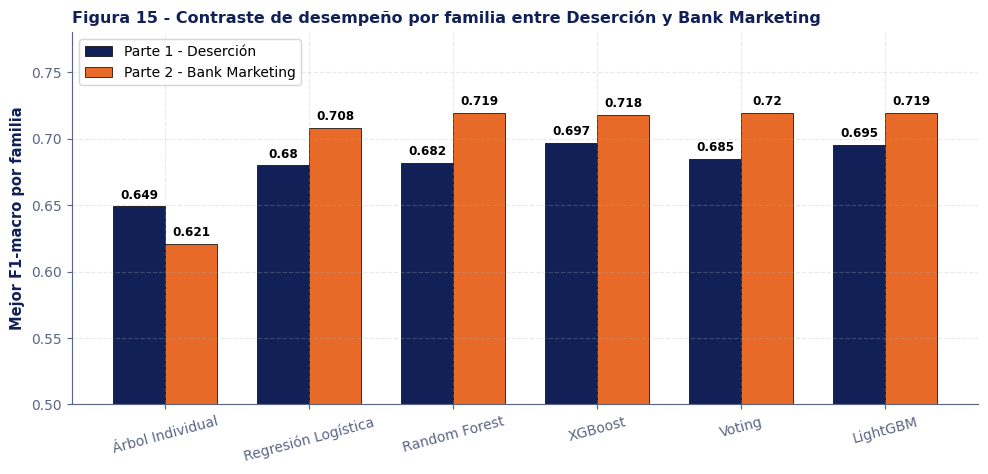

In [27]:
def f1_por_clave(df_tab, patron):
    sub = df_tab[df_tab["Modelo"].str.contains(patron, case=False, regex=True)]
    return float(sub["F1-macro"].max()) if len(sub) > 0 else 0.0

comp_df = pd.DataFrame({
    "Familia": ["Árbol Individual", "Regresión Logística", "Random Forest", "XGBoost", "Voting", "LightGBM"],
    "Deserción Estudiantil": [
        f1_por_clave(tabla_general_p1, "Árbol de decisión"),
        f1_por_clave(tabla_general_p1, "Regresión logística"),
        f1_por_clave(tabla_general_p1, "Random Forest"),
        f1_por_clave(tabla_general_p1, "XGBoost"),
        f1_por_clave(tabla_general_p1, "Votación"),
        f1_por_clave(tabla_general_p1, "LightGBM")
    ],
    "Bank Marketing": [
        f1_por_clave(tabla_general_bank, "Árbol de decisión"),
        f1_por_clave(tabla_general_bank, "Regresión logística"),
        f1_por_clave(tabla_general_bank, "Random Forest"),
        f1_por_clave(tabla_general_bank, "XGBoost"),
        f1_por_clave(tabla_general_bank, "Voting"),
        f1_por_clave(tabla_general_bank, "LightGBM")
    ]
})

fig, ax = plt.subplots(figsize=(9.5, 4.6))
x_pos = np.arange(len(comp_df))
ancho = 0.36
b1 = ax.bar(x_pos - ancho / 2, comp_df["Deserción Estudiantil"], width=ancho, color=AZUL_OSCURO, label="Parte 1 - Deserción", edgecolor="black", linewidth=0.5)
b2 = ax.bar(x_pos + ancho / 2, comp_df["Bank Marketing"], width=ancho, color=NARANJA, label="Parte 2 - Bank Marketing", edgecolor="black", linewidth=0.5)

for barra in list(b1) + list(b2):
    val = barra.get_height()
    ax.text(barra.get_x() + barra.get_width() / 2, val + 0.006, str(round(val, 3)), ha="center", fontsize=8.2, fontweight="bold")

ax.set_xticks(x_pos)
ax.set_xticklabels(comp_df["Familia"], rotation=15)
ax.set_ylim(0.50, 0.78)
ax.set_ylabel("Mejor F1-macro por familia")
ax.set_title("Figura 15 - Contraste de desempeño por familia entre Deserción y Bank Marketing")
ax.legend(loc="upper left", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


## Conclusiones Generales

1. **Valor agregado del meta-aprendizaje sobre clasificadores base sintonizados -** Cuando los modelos individuales ya recibieron optimización profunda de preprocesamiento e hiperparámetros (como ocurrió en la Práctica 3), las ganancias del ensamble existen (cerca de 1.5 puntos en $F_1$-macro con XGBoost y LightGBM optimizados hasta 0.6966 y 0.6952), confirmando que las representaciones lineales/kernel bien ajustadas ya capturaban buena parte de la señal lineal del primer semestre.
2. **Aporte diferenciado de cada familia -** Bagging demostró su papel estabilizador al reducir la varianza de árboles profundos (+7.8 puntos de $F_1$-macro al pasar de 0.5854 a 0.6630 con 300 árboles); Boosting redujo drásticamente el sesgo de tocones débiles (+15.2 puntos en AdaBoost desde 0.4920 hasta 0.6443); y la Votación dura capitalizó la baja correlación de errores entre familias diversas (0.362 entre Árbol y kNN).
3. **Impacto estructural de los datos en Bank Marketing -** Ante un volumen diez veces superior de observaciones, presencia de valores centinela (`pdays = 999`) y desbalance binario severo sin `duration`, el factor decisivo recayó en combinar ingeniería limpia dentro de `Pipeline`, ponderación moderada o optimización directa del umbral probabilístico (`TunedThresholdClassifierCV`) y algoritmos de ensamble regularizados, elevando el desempeño desde 0.6418 en Regresión logística base hasta 0.7195 en Voting Duro Optimizado (LGB+XGB+RF).


## Referencias Bibliográficas (Normas APA 7.ª Edición)

- Breiman, L. (1996). Bagging predictors. *Machine Learning*, *24*(2), 123–140. https://doi.org/10.1007/BF00058655
- Breiman, L. (2001). Random forests. *Machine Learning*, *45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE - Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research*, *16*, 321–357. https://doi.org/10.1613/jair.953
- Chen, T., & Guestrin, C. (2016). XGBoost - A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785
- Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, *55*(1), 119–139. https://doi.org/10.1006/jcss.1997.1504
- Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, *63*(1), 3–42. https://doi.org/10.1007/s10994-006-6226-1
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T. Y. (2017). LightGBM - A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, *30*, 3146–3154.
- Kuncheva, L. I. (2004). *Combining pattern classifiers - Methods and algorithms*. John Wiley & Sons.
- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, *62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
- Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn - Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830.
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, *7*(11), 146. https://doi.org/10.3390/data7110146
- Realinho, V., Martins, M. V., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
- Schapire, R. E., & Freund, Y. (2012). *Boosting - Foundations and algorithms*. MIT Press.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, *5*(2), 241–259. https://doi.org/10.1016/S0893-6080(05)80023-1

---

### Declaración de Apoyo Metodológico

Se utilizó asistencia automatizada como herramienta de apoyo en la revisión ortotipográfica, estructuración modular de código en Python y verificación experimental. Todos los procedimientos, selecciones de hiperparámetros, resultados numéricos e interpretaciones fueron ejecutados, validados y ajustados de manera reproducible dentro del entorno local.
